# 🎯 7. Modeling - Classification Supervisée Multi-Algorithmes

## Objectif
Appliquer et comparer différents algorithmes de classification supervisée pour prédire le Financial Profile des individus GenZ.

## Algorithmes à comparer
1. **SVM** (Support Vector Machine) - Classification par séparation optimale
2. **Decision Tree** (Arbre de Décision) - Modèle interprétable avec règles
3. **XGBoost** (Gradient Boosting) - Boosting avancé avec régularisation
4. **Random Forest** (Forêt Aléatoire) - Ensemble de décisions

## Plan d'analyse
1. Préparation des données et division train-test
2. Application et optimisation de chaque algorithme
3. Évaluation détaillée avec métriques et visualisations
4. Comparaison finale avec tableau synthétique
5. Conclusion et recommandation du meilleur modèle


In [1]:
# Importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, learning_curve
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_fscore_support
import warnings
import json
import time

warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Configuration pour l'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

print("📚 Bibliothèques importées avec succès!")


📚 Bibliothèques importées avec succès!


## 1. Chargement et Préparation des Données

**⚠️ IMPORTANT**: 
- Utilisation UNIQUEMENT des variables originales (sans ratios ni indices)
- Le Financial Profile est utilisé comme TARGET pour la classification
- Division train-test (80-20) avec stratification
- **Standardisation** : 
  - ✅ **SVM** utilise les données standardisées (nécessaire pour les algorithmes basés sur les distances)
  - ✅ **Decision Tree, XGBoost, Random Forest** utilisent les données non standardisées (les arbres n'en ont pas besoin)


In [2]:
# Chargement des données avec features
df = pd.read_csv('../data/processed/dataset_with_features.csv')

# ⚠️ IMPORTANT: Sélection UNIQUEMENT des variables originales
original_vars = [
    'Age', 'Income (USD)', 'Rent (USD)', 'Groceries (USD)', 
    'Eating Out (USD)', 'Entertainment (USD)', 'Subscription Services (USD)',
    'Education (USD)', 'Online Shopping (USD)', 'Savings (USD)', 
    'Investments (USD)', 'Travel (USD)', 'Fitness (USD)', 'Miscellaneous (USD)'
]

# Extraction des features et du target
X = df[original_vars].copy()
y = df['Financial_Profile'].copy()

# Encodage du target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Division train-test (80-20) avec stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Standardisation pour SVM uniquement
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"✅ Données chargées avec succès!")
print(f"📊 Dimensions: {X.shape[0]} lignes × {X.shape[1]} features")
print(f"\n🎯 Target: Financial_Profile")
print(f"📊 Distribution du target:")
print(y.value_counts())
print(f"\n📊 Classes encodées:")
for i, class_name in enumerate(le.classes_):
    print(f"   {i}: {class_name}")
print(f"\n✅ Division train-test effectuée!")
print(f"   Train: {X_train.shape[0]} échantillons")
print(f"   Test: {X_test.shape[0]} échantillons")
print(f"\n📊 Préparation des données:")
print(f"   ✅ Données standardisées créées pour SVM (X_train_scaled, X_test_scaled)")
print(f"   ✅ Données non standardisées pour arbres (X_train, X_test)")
print(f"   Note: Les arbres de décision n'ont pas besoin de standardisation")


✅ Données chargées avec succès!
📊 Dimensions: 6000 lignes × 14 features

🎯 Target: Financial_Profile
📊 Distribution du target:
Financial_Profile
Depensier       2258
Econome         1937
Equilibre       1471
Investisseur     334
Name: count, dtype: int64

📊 Classes encodées:
   0: Depensier
   1: Econome
   2: Equilibre
   3: Investisseur

✅ Division train-test effectuée!
   Train: 4800 échantillons
   Test: 1200 échantillons

📊 Préparation des données:
   ✅ Données standardisées créées pour SVM (X_train_scaled, X_test_scaled)
   ✅ Données non standardisées pour arbres (X_train, X_test)
   Note: Les arbres de décision n'ont pas besoin de standardisation


## 2. SVM - Support Vector Machine


🔄 Test des kernels SVM...

LINEAR:
   Accuracy: 0.954
   Precision: 0.954
   Recall: 0.954
   F1-Score: 0.954
   Temps d'entraînement: 0.53s

RBF:
   Accuracy: 0.943
   Precision: 0.943
   Recall: 0.943
   F1-Score: 0.943
   Temps d'entraînement: 1.45s

🎯 Meilleur kernel initial: LINEAR

🔄 Optimisation des hyperparamètres pour LINEAR...

✅ SVM - Résultats finaux:
   Kernel optimal: LINEAR
   Paramètres optimaux: {'C': 10}
   Score CV moyen: 0.964 (±0.003)
   Accuracy test: 0.959
   Precision: 0.959
   Recall: 0.959
   F1-Score: 0.959

📊 Métriques par classe:
   Depensier:
      Precision: 0.974
      Recall: 0.980
      F1-Score: 0.977
      Support: 452
   Econome:
      Precision: 0.974
      Recall: 0.974
      F1-Score: 0.974
      Support: 387
   Equilibre:
      Precision: 0.922
      Recall: 0.922
      F1-Score: 0.922
      Support: 294
   Investisseur:
      Precision: 0.938
      Recall: 0.896
      F1-Score: 0.916
      Support: 67


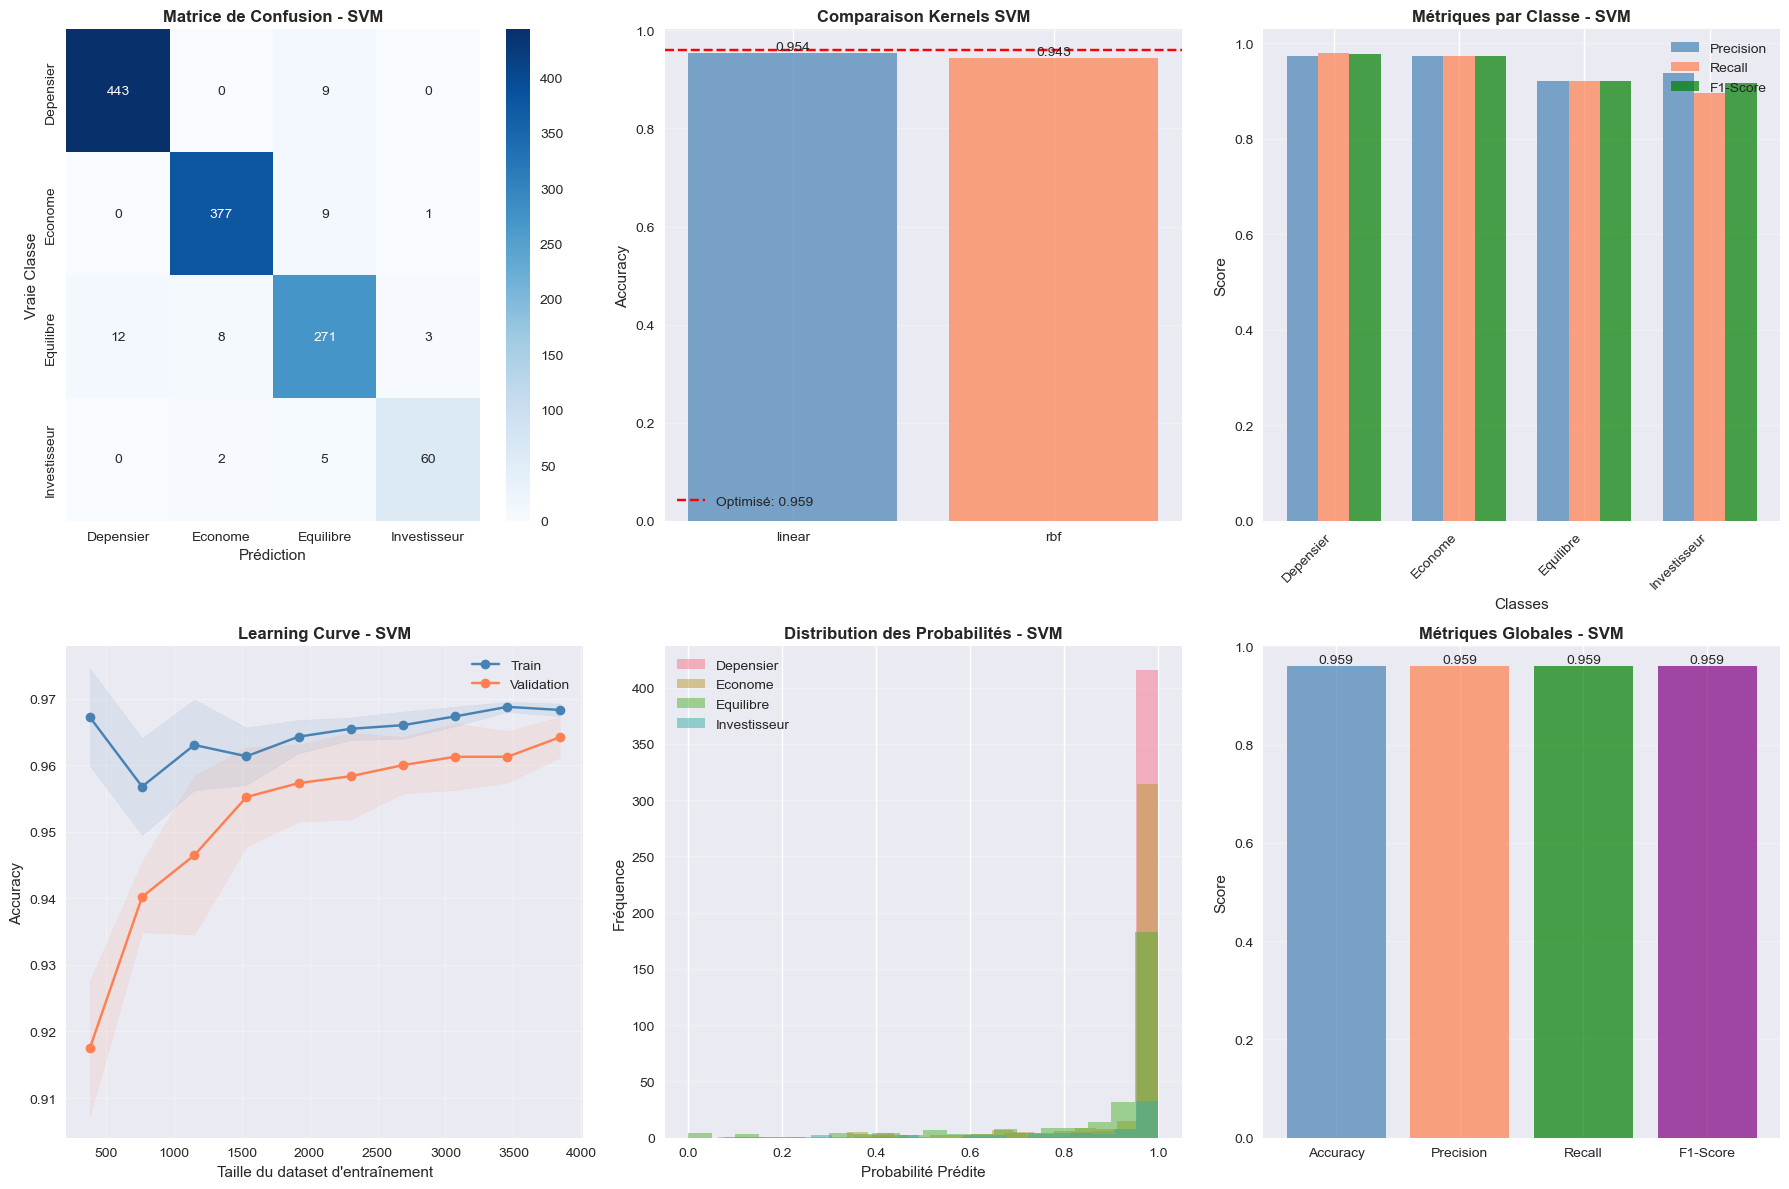


📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ - SVM
              precision    recall  f1-score   support

   Depensier       0.97      0.98      0.98       452
     Econome       0.97      0.97      0.97       387
   Equilibre       0.92      0.92      0.92       294
Investisseur       0.94      0.90      0.92        67

    accuracy                           0.96      1200
   macro avg       0.95      0.94      0.95      1200
weighted avg       0.96      0.96      0.96      1200


💡 INTERPRÉTATION DÉTAILLÉE SVM:
1. PERFORMANCE GLOBALE:
   - Accuracy de 95.9% indique que le modèle classe correctement
     95.9% des individus dans leur Financial Profile.
   - F1-Score de 0.959 montre un bon équilibre entre précision et rappel.
   - Score CV de 0.964 (±0.003) indique une bonne généralisation.

2. ANALYSE PAR CLASSE:
   Depensier:
      - Precision 0.974: Parmi les prédits Depensier, 97.4% sont corrects.
      - Recall 0.980: Le modèle identifie 98.0% des vrais Depensier.
   Econome:
      - Pre

In [3]:
# Test des kernels SVM
kernels = ['linear', 'rbf']
svm_results = {}

print("🔄 Test des kernels SVM...")
print("=" * 70)
for kernel in kernels:
    start_time = time.time()
    svm = SVC(kernel=kernel, random_state=42, probability=True)
    svm.fit(X_train_scaled, y_train)
    y_pred = svm.predict(X_test_scaled)
    train_time = time.time() - start_time
    
    # Métriques par classe
    precision_per_class, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
        y_test, y_pred, labels=[0, 1, 2, 3], zero_division=0
    )
    
    svm_results[kernel] = {
        'model': svm,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, average='weighted'),
        'recall': recall_score(y_test, y_pred, average='weighted'),
        'f1': f1_score(y_test, y_pred, average='weighted'),
        'precision_per_class': precision_per_class,
        'recall_per_class': recall_per_class,
        'f1_per_class': f1_per_class,
        'train_time': train_time
    }
    
    print(f"\n{kernel.upper()}:")
    print(f"   Accuracy: {svm_results[kernel]['accuracy']:.3f}")
    print(f"   Precision: {svm_results[kernel]['precision']:.3f}")
    print(f"   Recall: {svm_results[kernel]['recall']:.3f}")
    print(f"   F1-Score: {svm_results[kernel]['f1']:.3f}")
    print(f"   Temps d'entraînement: {train_time:.2f}s")

# Sélection du meilleur kernel
best_kernel = max(svm_results, key=lambda k: svm_results[k]['accuracy'])
print(f"\n🎯 Meilleur kernel initial: {best_kernel.upper()}")

# Optimisation des hyperparamètres
print(f"\n🔄 Optimisation des hyperparamètres pour {best_kernel.upper()}...")
param_grid = {'C': [1, 10, 100], 'gamma': ['scale', 0.01, 0.1]} if best_kernel == 'rbf' else {'C': [1, 10, 100]}
svm_opt = SVC(kernel=best_kernel, random_state=42, probability=True)
grid_svm = GridSearchCV(svm_opt, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=0)
grid_svm.fit(X_train_scaled, y_train)

# Prédictions avec le modèle optimisé
y_pred_svm = grid_svm.best_estimator_.predict(X_test_scaled)
y_pred_proba_svm = grid_svm.best_estimator_.predict_proba(X_test_scaled)

# Métriques finales détaillées
svm_metrics = {
    'accuracy': accuracy_score(y_test, y_pred_svm),
    'precision': precision_score(y_test, y_pred_svm, average='weighted'),
    'recall': recall_score(y_test, y_pred_svm, average='weighted'),
    'f1': f1_score(y_test, y_pred_svm, average='weighted')
}

# Métriques par classe
precision_per_class, recall_per_class, f1_per_class, support_per_class = precision_recall_fscore_support(
    y_test, y_pred_svm, labels=[0, 1, 2, 3], zero_division=0
)

# Cross-validation score
cv_scores_svm = cross_val_score(grid_svm.best_estimator_, X_train_scaled, y_train, cv=5, scoring='accuracy')

print(f"\n✅ SVM - Résultats finaux:")
print(f"   Kernel optimal: {best_kernel.upper()}")
print(f"   Paramètres optimaux: {grid_svm.best_params_}")
print(f"   Score CV moyen: {cv_scores_svm.mean():.3f} (±{cv_scores_svm.std():.3f})")
print(f"   Accuracy test: {svm_metrics['accuracy']:.3f}")
print(f"   Precision: {svm_metrics['precision']:.3f}")
print(f"   Recall: {svm_metrics['recall']:.3f}")
print(f"   F1-Score: {svm_metrics['f1']:.3f}")

print(f"\n📊 Métriques par classe:")
for i, class_name in enumerate(le.classes_):
    print(f"   {class_name}:")
    print(f"      Precision: {precision_per_class[i]:.3f}")
    print(f"      Recall: {recall_per_class[i]:.3f}")
    print(f"      F1-Score: {f1_per_class[i]:.3f}")
    print(f"      Support: {support_per_class[i]}")

# Visualisations détaillées
fig = plt.figure(figsize=(18, 12))

# Matrice de confusion
ax1 = plt.subplot(2, 3, 1)
cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax1)
ax1.set_title('Matrice de Confusion - SVM', fontweight='bold', fontsize=12)
ax1.set_xlabel('Prédiction')
ax1.set_ylabel('Vraie Classe')

# Comparaison des kernels
ax2 = plt.subplot(2, 3, 2)
kernel_names = list(svm_results.keys())
kernel_accs = [svm_results[k]['accuracy'] for k in kernel_names]
bars = ax2.bar(kernel_names, kernel_accs, color=['steelblue', 'coral'], alpha=0.7)
ax2.axhline(y=svm_metrics['accuracy'], color='r', linestyle='--', 
            label=f'Optimisé: {svm_metrics["accuracy"]:.3f}')
ax2.set_ylabel('Accuracy')
ax2.set_title('Comparaison Kernels SVM', fontweight='bold', fontsize=12)
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', 
            ha='center', va='bottom', fontsize=10)

# Métriques par classe
ax3 = plt.subplot(2, 3, 3)
x_pos = np.arange(len(le.classes_))
width = 0.25
ax3.bar(x_pos - width, precision_per_class, width, label='Precision', alpha=0.7, color='steelblue')
ax3.bar(x_pos, recall_per_class, width, label='Recall', alpha=0.7, color='coral')
ax3.bar(x_pos + width, f1_per_class, width, label='F1-Score', alpha=0.7, color='green')
ax3.set_xlabel('Classes')
ax3.set_ylabel('Score')
ax3.set_title('Métriques par Classe - SVM', fontweight='bold', fontsize=12)
ax3.set_xticks(x_pos)
ax3.set_xticklabels(le.classes_, rotation=45, ha='right')
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# Learning curve
ax4 = plt.subplot(2, 3, 4)
train_sizes, train_scores, val_scores = learning_curve(
    grid_svm.best_estimator_, X_train_scaled, y_train, cv=5, 
    train_sizes=np.linspace(0.1, 1.0, 10), scoring='accuracy', n_jobs=-1
)
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)
ax4.plot(train_sizes, train_mean, 'o-', color='steelblue', label='Train')
ax4.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='steelblue')
ax4.plot(train_sizes, val_mean, 'o-', color='coral', label='Validation')
ax4.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='coral')
ax4.set_xlabel('Taille du dataset d\'entraînement')
ax4.set_ylabel('Accuracy')
ax4.set_title('Learning Curve - SVM', fontweight='bold', fontsize=12)
ax4.legend()
ax4.grid(True, alpha=0.3)

# Distribution des probabilités prédites
ax5 = plt.subplot(2, 3, 5)
for i, class_name in enumerate(le.classes_):
    ax5.hist(y_pred_proba_svm[y_test == i, i], bins=20, alpha=0.5, label=class_name)
ax5.set_xlabel('Probabilité Prédite')
ax5.set_ylabel('Fréquence')
ax5.set_title('Distribution des Probabilités - SVM', fontweight='bold', fontsize=12)
ax5.legend()
ax5.grid(True, alpha=0.3, axis='y')

# Comparaison des métriques
ax6 = plt.subplot(2, 3, 6)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metrics_values = [svm_metrics['accuracy'], svm_metrics['precision'], 
                  svm_metrics['recall'], svm_metrics['f1']]
bars = ax6.bar(metrics_names, metrics_values, color=['steelblue', 'coral', 'green', 'purple'], alpha=0.7)
ax6.set_ylabel('Score')
ax6.set_title('Métriques Globales - SVM', fontweight='bold', fontsize=12)
ax6.set_ylim([0, 1])
ax6.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', 
            ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../data/results/svm_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Rapport de classification détaillé
print("\n" + "=" * 70)
print("📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ - SVM")
print("=" * 70)
print(classification_report(y_test, y_pred_svm, target_names=le.classes_))

print("\n💡 INTERPRÉTATION DÉTAILLÉE SVM:")
print("=" * 70)
print(f"1. PERFORMANCE GLOBALE:")
print(f"   - Accuracy de {svm_metrics['accuracy']:.1%} indique que le modèle classe correctement")
print(f"     {svm_metrics['accuracy']*100:.1f}% des individus dans leur Financial Profile.")
print(f"   - F1-Score de {svm_metrics['f1']:.3f} montre un bon équilibre entre précision et rappel.")
print(f"   - Score CV de {cv_scores_svm.mean():.3f} (±{cv_scores_svm.std():.3f}) indique une bonne généralisation.")

print(f"\n2. ANALYSE PAR CLASSE:")
for i, class_name in enumerate(le.classes_):
    print(f"   {class_name}:")
    print(f"      - Precision {precision_per_class[i]:.3f}: Parmi les prédits {class_name}, {precision_per_class[i]*100:.1f}% sont corrects.")
    print(f"      - Recall {recall_per_class[i]:.3f}: Le modèle identifie {recall_per_class[i]*100:.1f}% des vrais {class_name}.")
    if f1_per_class[i] < 0.7:
        print(f"      ⚠️ F1-Score faible ({f1_per_class[i]:.3f}) - classe potentiellement sous-représentée")

print(f"\n3. CARACTÉRISTIQUES DU MODÈLE:")
print(f"   - Kernel {best_kernel.upper()}: {'Adapté aux relations non-linéaires' if best_kernel == 'rbf' else 'Séparation linéaire optimale'}")
print(f"   - Paramètre C={grid_svm.best_params_.get('C', 'N/A')}: {'Régularisation modérée' if grid_svm.best_params_.get('C', 1) < 50 else 'Régularisation faible (risque de sur-apprentissage)'}")
print(f"   - Le modèle utilise les marges maximales pour séparer les classes.")
print(f"   - Standardisation: SVM est sensible aux échelles des variables, c'est pourquoi")
print(f"     les données ont été standardisées (X_train_scaled, X_test_scaled) avant l'entraînement.")


## 3. Decision Tree - Arbre de Décision


🔄 Optimisation Decision Tree...

✅ Decision Tree - Résultats finaux:
   Paramètres optimaux: {'max_depth': 20, 'min_samples_leaf': 4, 'min_samples_split': 2}
   Score CV moyen: 0.916 (±0.004)
   Accuracy test: 0.923
   Precision: 0.924
   Recall: 0.923
   F1-Score: 0.923
   Temps d'entraînement: 2.10s
   Profondeur de l'arbre: 13
   Nombre de feuilles: 173

📊 Métriques par classe:
   Depensier: Precision=0.978, Recall=0.967, F1=0.972
   Econome: Precision=0.914, Recall=0.933, F1=0.923
   Equilibre: Precision=0.859, Recall=0.867, F1=0.863
   Investisseur: Precision=0.902, Recall=0.821, F1=0.859


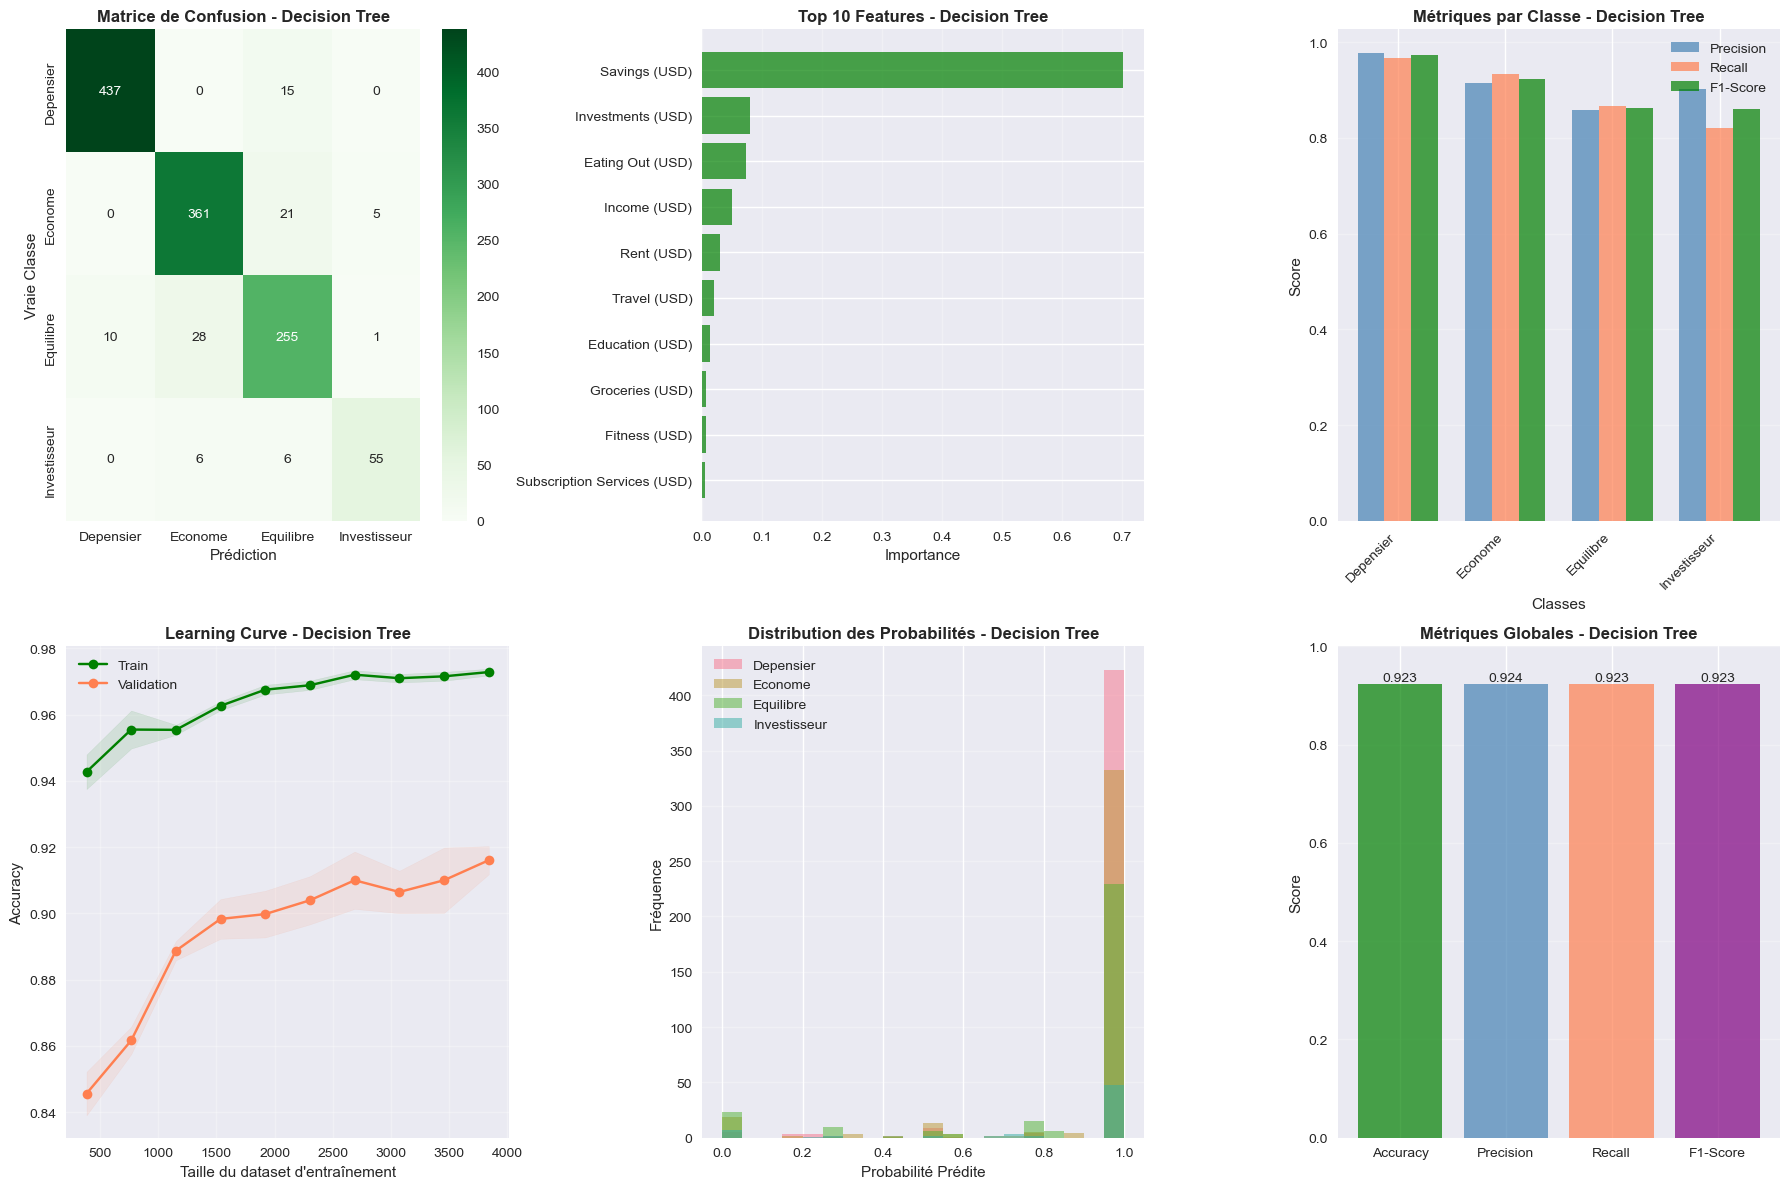


🌳 Visualisation de l'Arbre de Décision...


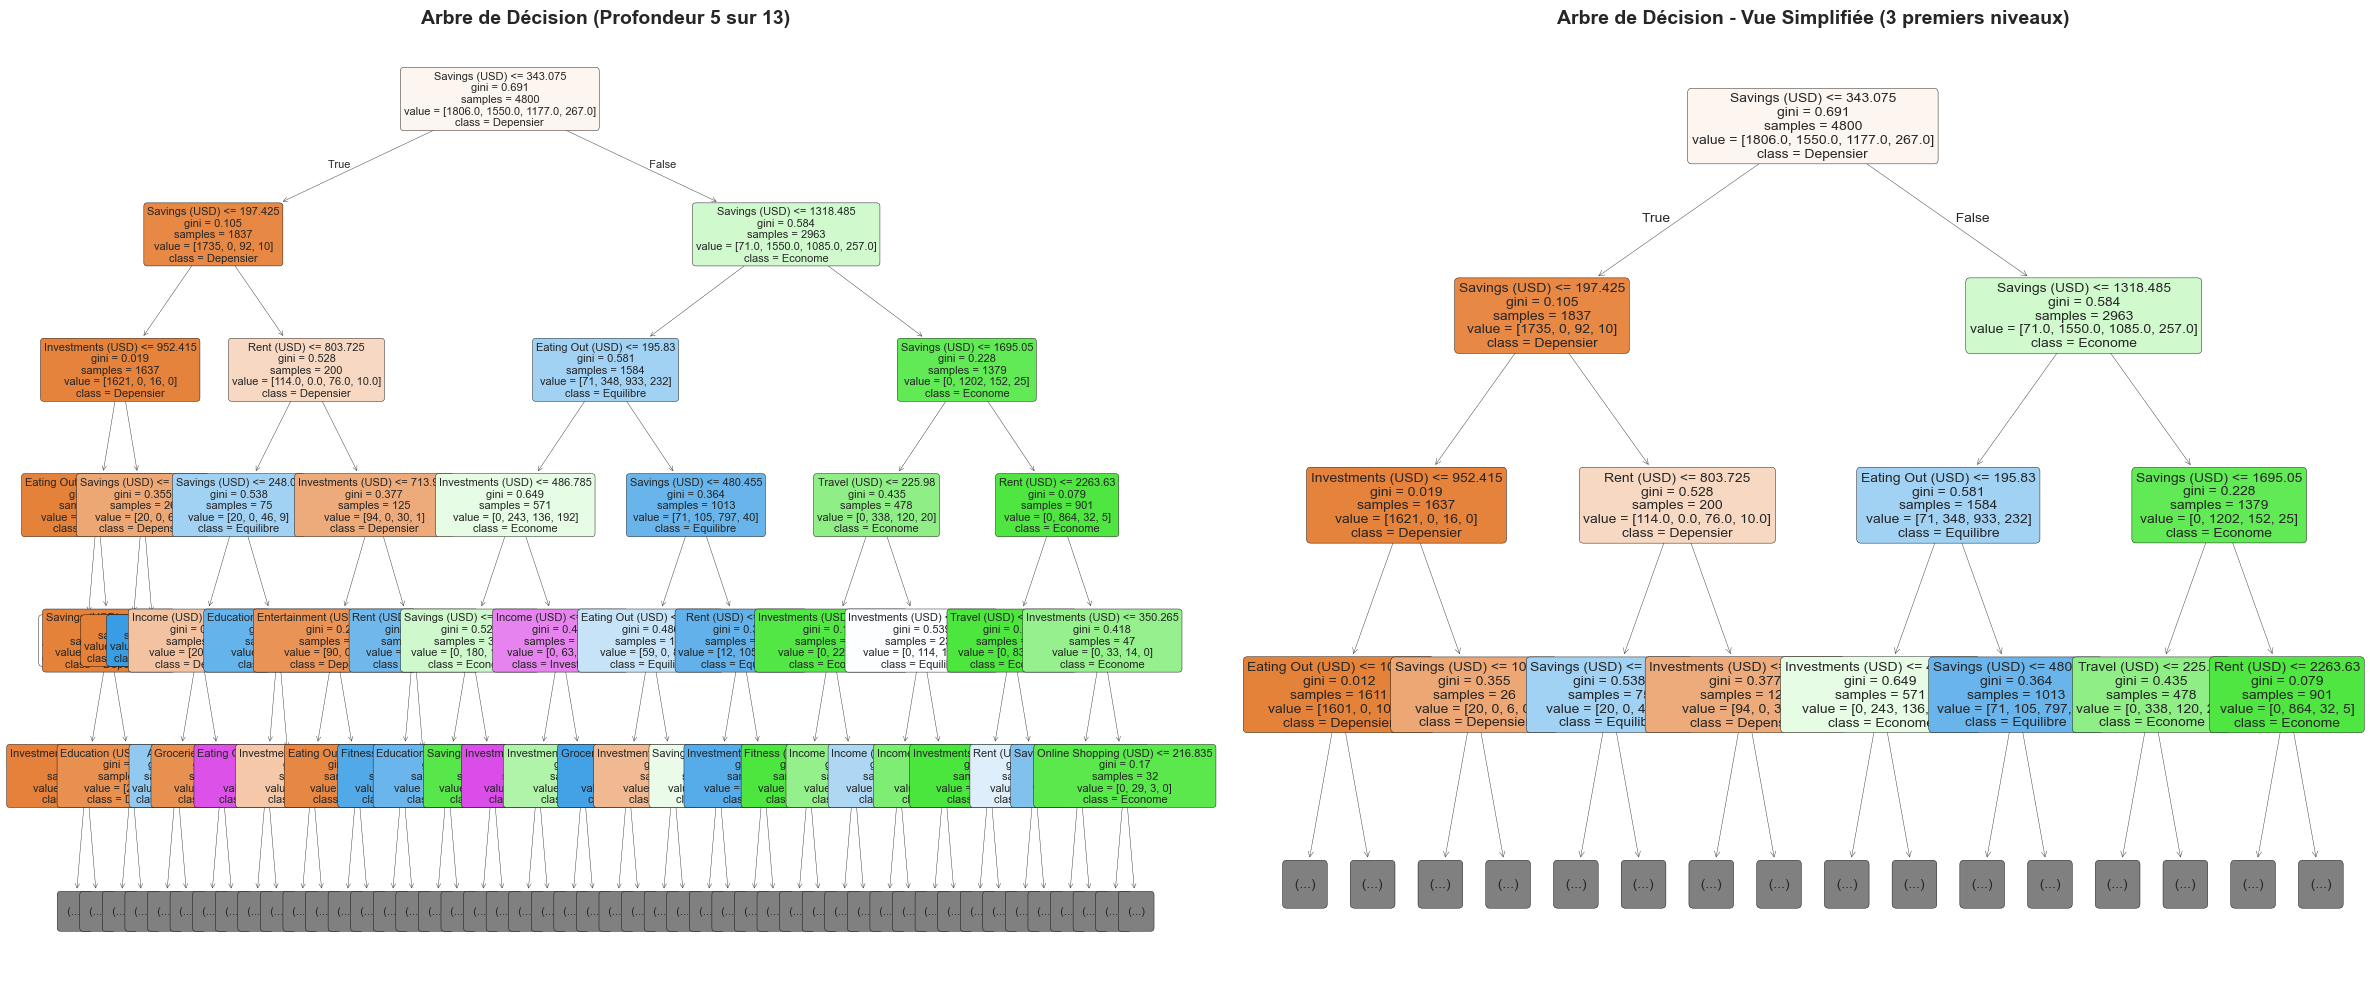

✅ Arbre visualisé (profondeur totale: 13, feuilles: 173)

📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ - Decision Tree
              precision    recall  f1-score   support

   Depensier       0.98      0.97      0.97       452
     Econome       0.91      0.93      0.92       387
   Equilibre       0.86      0.87      0.86       294
Investisseur       0.90      0.82      0.86        67

    accuracy                           0.92      1200
   macro avg       0.91      0.90      0.90      1200
weighted avg       0.92      0.92      0.92      1200


💡 INTERPRÉTATION DÉTAILLÉE Decision Tree:
1. PERFORMANCE GLOBALE:
   - Accuracy de 92.3%: Le modèle classe correctement 92.3% des individus.
   - F1-Score de 0.923 montre un équilibre bon entre précision et rappel.
   - Score CV de 0.916 (±0.004) indique une généralisation stable.

2. STRUCTURE DE L'ARBRE:
   - Profondeur: 13 niveaux
   - Nombre de feuilles: 173
   - Arbre de profondeur modérée - Bonne régularisation

3. IMPORTANCE DES FEATURES:
   

In [4]:
# Optimisation de l'arbre de décision
print("🔄 Optimisation Decision Tree...")
print("=" * 70)
param_grid_dt = {
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

start_time = time.time()
dt_base = DecisionTreeClassifier(random_state=42)
grid_dt = GridSearchCV(dt_base, param_grid_dt, cv=5, scoring='accuracy', n_jobs=-1, verbose=0)
grid_dt.fit(X_train, y_train)
train_time_dt = time.time() - start_time

# Prédictions
y_pred_dt = grid_dt.best_estimator_.predict(X_test)
y_pred_proba_dt = grid_dt.best_estimator_.predict_proba(X_test)

# Métriques détaillées
dt_metrics = {
    'accuracy': accuracy_score(y_test, y_pred_dt),
    'precision': precision_score(y_test, y_pred_dt, average='weighted'),
    'recall': recall_score(y_test, y_pred_dt, average='weighted'),
    'f1': f1_score(y_test, y_pred_dt, average='weighted')
}

# Métriques par classe
precision_per_class, recall_per_class, f1_per_class, support_per_class = precision_recall_fscore_support(
    y_test, y_pred_dt, labels=[0, 1, 2, 3], zero_division=0
)

# Cross-validation
cv_scores_dt = cross_val_score(grid_dt.best_estimator_, X_train, y_train, cv=5, scoring='accuracy')

# Importance des features
feature_importance_dt = pd.DataFrame({
    'Feature': original_vars,
    'Importance': grid_dt.best_estimator_.feature_importances_
}).sort_values('Importance', ascending=False)

print(f"\n✅ Decision Tree - Résultats finaux:")
print(f"   Paramètres optimaux: {grid_dt.best_params_}")
print(f"   Score CV moyen: {cv_scores_dt.mean():.3f} (±{cv_scores_dt.std():.3f})")
print(f"   Accuracy test: {dt_metrics['accuracy']:.3f}")
print(f"   Precision: {dt_metrics['precision']:.3f}")
print(f"   Recall: {dt_metrics['recall']:.3f}")
print(f"   F1-Score: {dt_metrics['f1']:.3f}")
print(f"   Temps d'entraînement: {train_time_dt:.2f}s")
print(f"   Profondeur de l'arbre: {grid_dt.best_estimator_.get_depth()}")
print(f"   Nombre de feuilles: {grid_dt.best_estimator_.get_n_leaves()}")

print(f"\n📊 Métriques par classe:")
for i, class_name in enumerate(le.classes_):
    print(f"   {class_name}: Precision={precision_per_class[i]:.3f}, Recall={recall_per_class[i]:.3f}, F1={f1_per_class[i]:.3f}")

# Visualisations détaillées
fig = plt.figure(figsize=(18, 12))

# Matrice de confusion
ax1 = plt.subplot(2, 3, 1)
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens', 
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax1)
ax1.set_title('Matrice de Confusion - Decision Tree', fontweight='bold', fontsize=12)
ax1.set_xlabel('Prédiction')
ax1.set_ylabel('Vraie Classe')

# Importance des features (top 10)
ax2 = plt.subplot(2, 3, 2)
top_features = feature_importance_dt.head(10).sort_values('Importance', ascending=True)
ax2.barh(top_features['Feature'], top_features['Importance'], color='green', alpha=0.7)
ax2.set_xlabel('Importance')
ax2.set_title('Top 10 Features - Decision Tree', fontweight='bold', fontsize=12)
ax2.grid(True, alpha=0.3, axis='x')

# Métriques par classe
ax3 = plt.subplot(2, 3, 3)
x_pos = np.arange(len(le.classes_))
width = 0.25
ax3.bar(x_pos - width, precision_per_class, width, label='Precision', alpha=0.7, color='steelblue')
ax3.bar(x_pos, recall_per_class, width, label='Recall', alpha=0.7, color='coral')
ax3.bar(x_pos + width, f1_per_class, width, label='F1-Score', alpha=0.7, color='green')
ax3.set_xlabel('Classes')
ax3.set_ylabel('Score')
ax3.set_title('Métriques par Classe - Decision Tree', fontweight='bold', fontsize=12)
ax3.set_xticks(x_pos)
ax3.set_xticklabels(le.classes_, rotation=45, ha='right')
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# Learning curve
ax4 = plt.subplot(2, 3, 4)
train_sizes, train_scores, val_scores = learning_curve(
    grid_dt.best_estimator_, X_train, y_train, cv=5, 
    train_sizes=np.linspace(0.1, 1.0, 10), scoring='accuracy', n_jobs=-1
)
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)
ax4.plot(train_sizes, train_mean, 'o-', color='green', label='Train')
ax4.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='green')
ax4.plot(train_sizes, val_mean, 'o-', color='coral', label='Validation')
ax4.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='coral')
ax4.set_xlabel('Taille du dataset d\'entraînement')
ax4.set_ylabel('Accuracy')
ax4.set_title('Learning Curve - Decision Tree', fontweight='bold', fontsize=12)
ax4.legend()
ax4.grid(True, alpha=0.3)

# Distribution des probabilités
ax5 = plt.subplot(2, 3, 5)
for i, class_name in enumerate(le.classes_):
    ax5.hist(y_pred_proba_dt[y_test == i, i], bins=20, alpha=0.5, label=class_name)
ax5.set_xlabel('Probabilité Prédite')
ax5.set_ylabel('Fréquence')
ax5.set_title('Distribution des Probabilités - Decision Tree', fontweight='bold', fontsize=12)
ax5.legend()
ax5.grid(True, alpha=0.3, axis='y')

# Comparaison des métriques
ax6 = plt.subplot(2, 3, 6)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metrics_values = [dt_metrics['accuracy'], dt_metrics['precision'], 
                  dt_metrics['recall'], dt_metrics['f1']]
bars = ax6.bar(metrics_names, metrics_values, color=['green', 'steelblue', 'coral', 'purple'], alpha=0.7)
ax6.set_ylabel('Score')
ax6.set_title('Métriques Globales - Decision Tree', fontweight='bold', fontsize=12)
ax6.set_ylim([0, 1])
ax6.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', 
            ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../data/results/decision_tree_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Visualisation de l'arbre de décision
print("\n🌳 Visualisation de l'Arbre de Décision...")
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

# Arbre complet (limité à une profondeur raisonnable pour la lisibilité)
max_depth_viz = min(5, grid_dt.best_estimator_.get_depth())
plot_tree(grid_dt.best_estimator_, 
          max_depth=max_depth_viz,
          feature_names=original_vars,
          class_names=le.classes_,
          filled=True,
          rounded=True,
          fontsize=8,
          ax=axes[0])
axes[0].set_title(f'Arbre de Décision (Profondeur {max_depth_viz} sur {grid_dt.best_estimator_.get_depth()})', 
                  fontweight='bold', fontsize=14)

# Arbre simplifié (premiers niveaux seulement)
plot_tree(grid_dt.best_estimator_, 
          max_depth=3,
          feature_names=original_vars,
          class_names=le.classes_,
          filled=True,
          rounded=True,
          fontsize=10,
          ax=axes[1])
axes[1].set_title('Arbre de Décision - Vue Simplifiée (3 premiers niveaux)', 
                  fontweight='bold', fontsize=14)

plt.tight_layout()
plt.savefig('../data/results/decision_tree_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Arbre visualisé (profondeur totale: {grid_dt.best_estimator_.get_depth()}, feuilles: {grid_dt.best_estimator_.get_n_leaves()})")

# Rapport de classification
print("\n" + "=" * 70)
print("📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ - Decision Tree")
print("=" * 70)
print(classification_report(y_test, y_pred_dt, target_names=le.classes_))

print("\n💡 INTERPRÉTATION DÉTAILLÉE Decision Tree:")
print("=" * 70)
print(f"1. PERFORMANCE GLOBALE:")
print(f"   - Accuracy de {dt_metrics['accuracy']:.1%}: Le modèle classe correctement {dt_metrics['accuracy']*100:.1f}% des individus.")
print(f"   - F1-Score de {dt_metrics['f1']:.3f} montre un équilibre {'bon' if dt_metrics['f1'] > 0.9 else 'modéré'} entre précision et rappel.")
print(f"   - Score CV de {cv_scores_dt.mean():.3f} (±{cv_scores_dt.std():.3f}) indique une généralisation {'stable' if cv_scores_dt.std() < 0.02 else 'variable'}.")

print(f"\n2. STRUCTURE DE L'ARBRE:")
print(f"   - Profondeur: {grid_dt.best_estimator_.get_depth()} niveaux")
print(f"   - Nombre de feuilles: {grid_dt.best_estimator_.get_n_leaves()}")
print(f"   - {'Arbre profond' if grid_dt.best_estimator_.get_depth() > 20 else 'Arbre de profondeur modérée'} - {'Risque de sur-apprentissage' if grid_dt.best_estimator_.get_depth() > 20 else 'Bonne régularisation'}")

print(f"\n3. IMPORTANCE DES FEATURES:")
print(f"   - Top 3 features les plus importantes:")
for idx, row in feature_importance_dt.head(3).iterrows():
    print(f"      {row['Feature']}: {row['Importance']:.3f} ({row['Importance']*100:.1f}%)")

print(f"\n4. ANALYSE PAR CLASSE:")
for i, class_name in enumerate(le.classes_):
    print(f"   {class_name}:")
    print(f"      - Precision {precision_per_class[i]:.3f}: {precision_per_class[i]*100:.1f}% des prédictions {class_name} sont correctes")
    print(f"      - Recall {recall_per_class[i]:.3f}: {recall_per_class[i]*100:.1f}% des vrais {class_name} sont identifiés")
    if f1_per_class[i] < 0.7:
        print(f"      ⚠️ Performance faible pour cette classe (F1={f1_per_class[i]:.3f})")

print(f"\n5. AVANTAGES ET LIMITATIONS:")
print(f"   ✅ Avantages: Modèle très interprétable, règles de décision claires")
print(f"   ✅ Rapidité: Temps d'entraînement de {train_time_dt:.2f}s")
print(f"   ⚠️ Limitation: {'Risque de sur-apprentissage' if grid_dt.best_estimator_.get_depth() > 20 else 'Profondeur contrôlée'}")


## 4. XGBoost - Gradient Boosting


🔄 Optimisation XGBoost...

✅ XGBoost - Résultats finaux:
   Paramètres optimaux: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 100}
   Score CV moyen: 0.945 (±0.002)
   Accuracy test: 0.954
   Precision: 0.954
   Recall: 0.954
   F1-Score: 0.954
   Temps d'entraînement: 11.75s
   Nombre d'estimateurs: 100

📊 Métriques par classe:
   Depensier: Precision=0.987, Recall=0.991, F1=0.989
   Econome: Precision=0.939, Recall=0.948, F1=0.943
   Equilibre: Precision=0.934, Recall=0.908, F1=0.921
   Investisseur: Precision=0.913, Recall=0.940, F1=0.926


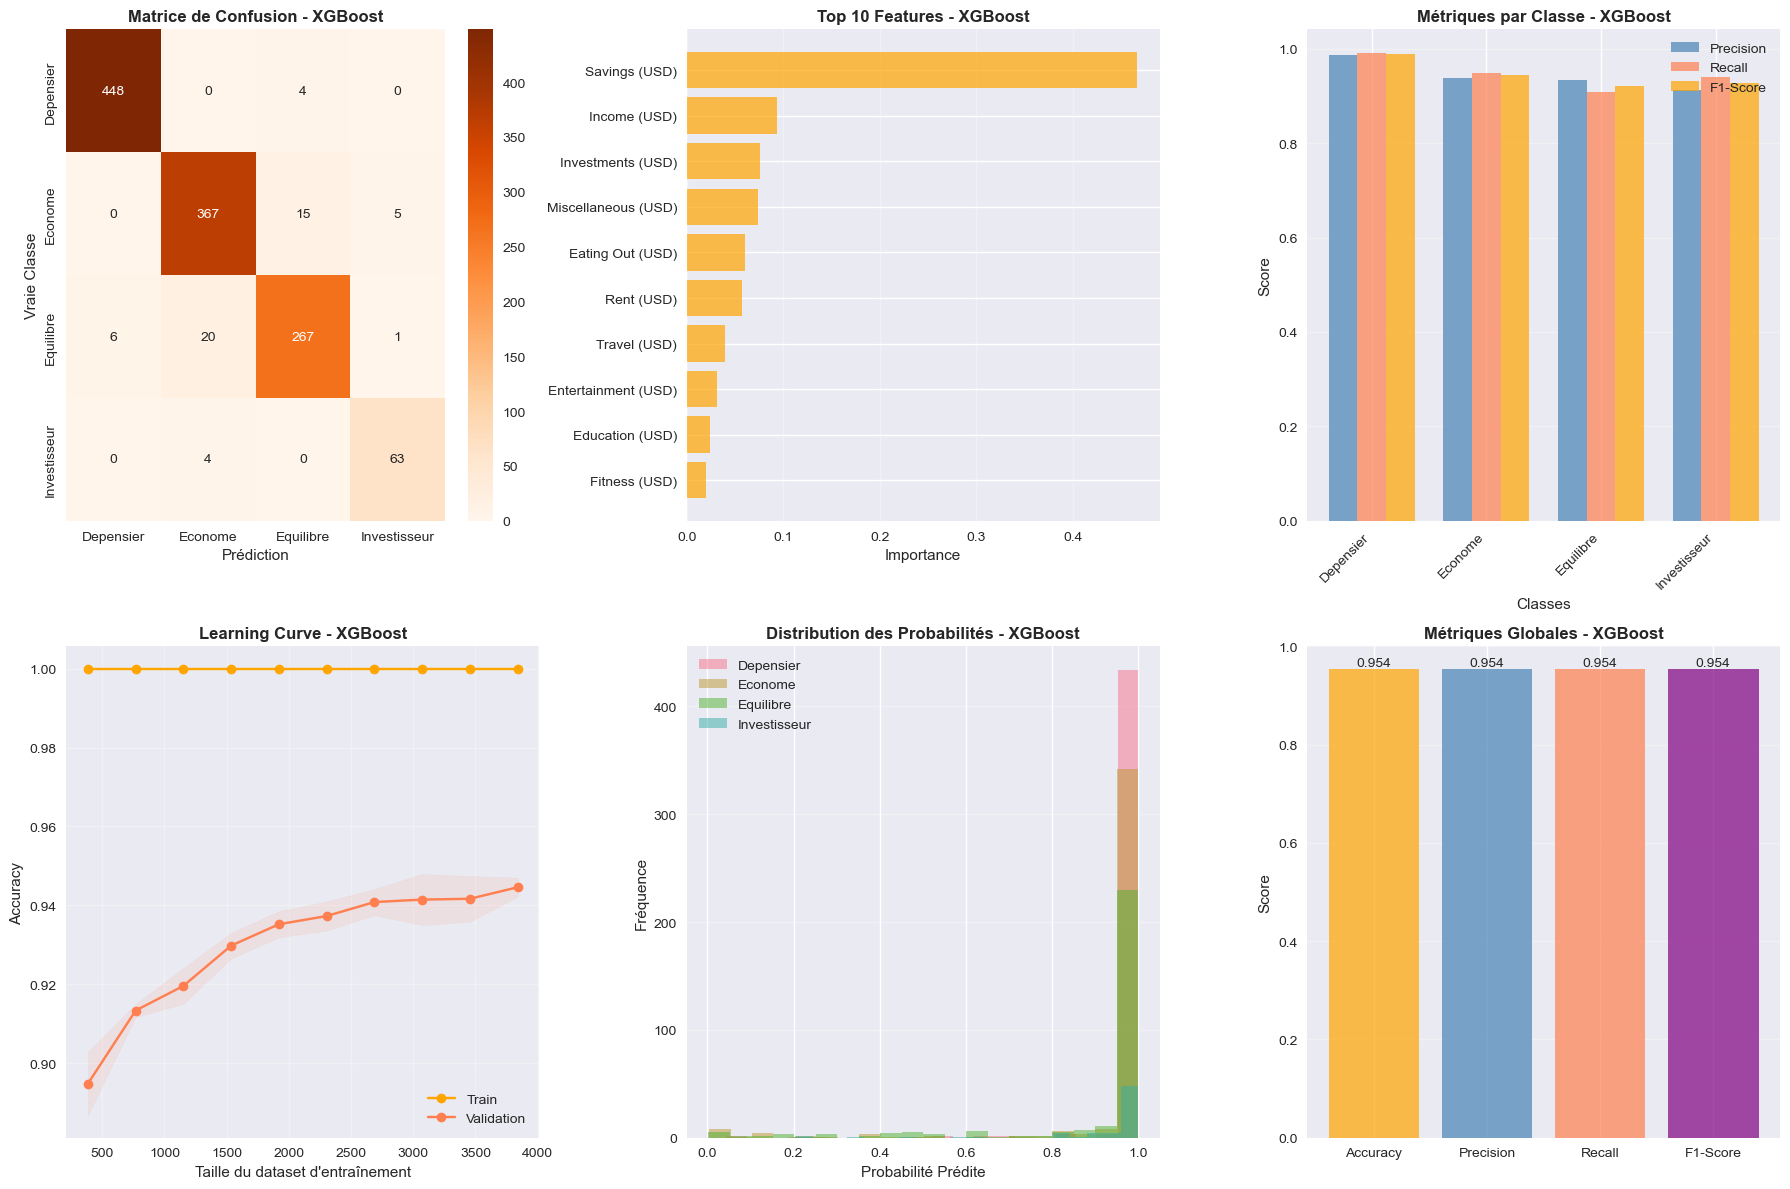


📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ - XGBoost
              precision    recall  f1-score   support

   Depensier       0.99      0.99      0.99       452
     Econome       0.94      0.95      0.94       387
   Equilibre       0.93      0.91      0.92       294
Investisseur       0.91      0.94      0.93        67

    accuracy                           0.95      1200
   macro avg       0.94      0.95      0.94      1200
weighted avg       0.95      0.95      0.95      1200


💡 INTERPRÉTATION DÉTAILLÉE XGBoost:
1. PERFORMANCE GLOBALE:
   - Accuracy de 95.4%: Classification correcte de 95.4% des individus.
   - F1-Score de 0.954 indique un excellent équilibre précision/rappel.
   - Score CV de 0.945 (±0.002) montre une généralisation très stable.

2. CONFIGURATION DU MODÈLE:
   - Learning rate: 0.2 (modéré)
   - Profondeur max: 7 niveaux
   - Nombre d'estimateurs: 100 arbres
   - Temps d'entraînement: 11.75s

3. IMPORTANCE DES FEATURES:
   - Top 3 features les plus importantes:
     

In [5]:
# Optimisation XGBoost
print("🔄 Optimisation XGBoost...")
print("=" * 70)
param_grid_xgb = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2]
}

start_time = time.time()
xgb_base = XGBClassifier(random_state=42, eval_metric='mlogloss')
grid_xgb = GridSearchCV(xgb_base, param_grid_xgb, cv=5, scoring='accuracy', n_jobs=-1, verbose=0)
grid_xgb.fit(X_train, y_train)
train_time_xgb = time.time() - start_time

# Prédictions
y_pred_xgb = grid_xgb.best_estimator_.predict(X_test)
y_pred_proba_xgb = grid_xgb.best_estimator_.predict_proba(X_test)

# Métriques détaillées
xgb_metrics = {
    'accuracy': accuracy_score(y_test, y_pred_xgb),
    'precision': precision_score(y_test, y_pred_xgb, average='weighted'),
    'recall': recall_score(y_test, y_pred_xgb, average='weighted'),
    'f1': f1_score(y_test, y_pred_xgb, average='weighted')
}

# Métriques par classe
precision_per_class, recall_per_class, f1_per_class, support_per_class = precision_recall_fscore_support(
    y_test, y_pred_xgb, labels=[0, 1, 2, 3], zero_division=0
)

# Cross-validation
cv_scores_xgb = cross_val_score(grid_xgb.best_estimator_, X_train, y_train, cv=5, scoring='accuracy')

# Importance des features
feature_importance_xgb = pd.DataFrame({
    'Feature': original_vars,
    'Importance': grid_xgb.best_estimator_.feature_importances_
}).sort_values('Importance', ascending=False)

print(f"\n✅ XGBoost - Résultats finaux:")
print(f"   Paramètres optimaux: {grid_xgb.best_params_}")
print(f"   Score CV moyen: {cv_scores_xgb.mean():.3f} (±{cv_scores_xgb.std():.3f})")
print(f"   Accuracy test: {xgb_metrics['accuracy']:.3f}")
print(f"   Precision: {xgb_metrics['precision']:.3f}")
print(f"   Recall: {xgb_metrics['recall']:.3f}")
print(f"   F1-Score: {xgb_metrics['f1']:.3f}")
print(f"   Temps d'entraînement: {train_time_xgb:.2f}s")
print(f"   Nombre d'estimateurs: {grid_xgb.best_params_['n_estimators']}")

print(f"\n📊 Métriques par classe:")
for i, class_name in enumerate(le.classes_):
    print(f"   {class_name}: Precision={precision_per_class[i]:.3f}, Recall={recall_per_class[i]:.3f}, F1={f1_per_class[i]:.3f}")

# Visualisations détaillées
fig = plt.figure(figsize=(18, 12))

# Matrice de confusion
ax1 = plt.subplot(2, 3, 1)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax1)
ax1.set_title('Matrice de Confusion - XGBoost', fontweight='bold', fontsize=12)
ax1.set_xlabel('Prédiction')
ax1.set_ylabel('Vraie Classe')

# Importance des features (top 10)
ax2 = plt.subplot(2, 3, 2)
top_features = feature_importance_xgb.head(10).sort_values('Importance', ascending=True)
ax2.barh(top_features['Feature'], top_features['Importance'], color='orange', alpha=0.7)
ax2.set_xlabel('Importance')
ax2.set_title('Top 10 Features - XGBoost', fontweight='bold', fontsize=12)
ax2.grid(True, alpha=0.3, axis='x')

# Métriques par classe
ax3 = plt.subplot(2, 3, 3)
x_pos = np.arange(len(le.classes_))
width = 0.25
ax3.bar(x_pos - width, precision_per_class, width, label='Precision', alpha=0.7, color='steelblue')
ax3.bar(x_pos, recall_per_class, width, label='Recall', alpha=0.7, color='coral')
ax3.bar(x_pos + width, f1_per_class, width, label='F1-Score', alpha=0.7, color='orange')
ax3.set_xlabel('Classes')
ax3.set_ylabel('Score')
ax3.set_title('Métriques par Classe - XGBoost', fontweight='bold', fontsize=12)
ax3.set_xticks(x_pos)
ax3.set_xticklabels(le.classes_, rotation=45, ha='right')
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# Learning curve
ax4 = plt.subplot(2, 3, 4)
train_sizes, train_scores, val_scores = learning_curve(
    grid_xgb.best_estimator_, X_train, y_train, cv=5, 
    train_sizes=np.linspace(0.1, 1.0, 10), scoring='accuracy', n_jobs=-1
)
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)
ax4.plot(train_sizes, train_mean, 'o-', color='orange', label='Train')
ax4.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='orange')
ax4.plot(train_sizes, val_mean, 'o-', color='coral', label='Validation')
ax4.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='coral')
ax4.set_xlabel('Taille du dataset d\'entraînement')
ax4.set_ylabel('Accuracy')
ax4.set_title('Learning Curve - XGBoost', fontweight='bold', fontsize=12)
ax4.legend()
ax4.grid(True, alpha=0.3)

# Distribution des probabilités
ax5 = plt.subplot(2, 3, 5)
for i, class_name in enumerate(le.classes_):
    ax5.hist(y_pred_proba_xgb[y_test == i, i], bins=20, alpha=0.5, label=class_name)
ax5.set_xlabel('Probabilité Prédite')
ax5.set_ylabel('Fréquence')
ax5.set_title('Distribution des Probabilités - XGBoost', fontweight='bold', fontsize=12)
ax5.legend()
ax5.grid(True, alpha=0.3, axis='y')

# Comparaison des métriques
ax6 = plt.subplot(2, 3, 6)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metrics_values = [xgb_metrics['accuracy'], xgb_metrics['precision'], 
                  xgb_metrics['recall'], xgb_metrics['f1']]
bars = ax6.bar(metrics_names, metrics_values, color=['orange', 'steelblue', 'coral', 'purple'], alpha=0.7)
ax6.set_ylabel('Score')
ax6.set_title('Métriques Globales - XGBoost', fontweight='bold', fontsize=12)
ax6.set_ylim([0, 1])
ax6.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', 
            ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../data/results/xgboost_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Rapport de classification
print("\n" + "=" * 70)
print("📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ - XGBoost")
print("=" * 70)
print(classification_report(y_test, y_pred_xgb, target_names=le.classes_))

print("\n💡 INTERPRÉTATION DÉTAILLÉE XGBoost:")
print("=" * 70)
print(f"1. PERFORMANCE GLOBALE:")
print(f"   - Accuracy de {xgb_metrics['accuracy']:.1%}: Classification correcte de {xgb_metrics['accuracy']*100:.1f}% des individus.")
print(f"   - F1-Score de {xgb_metrics['f1']:.3f} indique un {'excellent' if xgb_metrics['f1'] > 0.93 else 'bon'} équilibre précision/rappel.")
print(f"   - Score CV de {cv_scores_xgb.mean():.3f} (±{cv_scores_xgb.std():.3f}) montre une généralisation {'très stable' if cv_scores_xgb.std() < 0.015 else 'stable'}.")

print(f"\n2. CONFIGURATION DU MODÈLE:")
print(f"   - Learning rate: {grid_xgb.best_params_['learning_rate']} ({'conservateur' if grid_xgb.best_params_['learning_rate'] < 0.1 else 'modéré'})")
print(f"   - Profondeur max: {grid_xgb.best_params_['max_depth']} niveaux")
print(f"   - Nombre d'estimateurs: {grid_xgb.best_params_['n_estimators']} arbres")
print(f"   - Temps d'entraînement: {train_time_xgb:.2f}s")

print(f"\n3. IMPORTANCE DES FEATURES:")
print(f"   - Top 3 features les plus importantes:")
for idx, row in feature_importance_xgb.head(3).iterrows():
    print(f"      {row['Feature']}: {row['Importance']:.3f} ({row['Importance']*100:.1f}%)")

print(f"\n4. ANALYSE PAR CLASSE:")
for i, class_name in enumerate(le.classes_):
    print(f"   {class_name}:")
    print(f"      - Precision {precision_per_class[i]:.3f}: {precision_per_class[i]*100:.1f}% des prédictions sont correctes")
    print(f"      - Recall {recall_per_class[i]:.3f}: {recall_per_class[i]*100:.1f}% des vrais cas sont détectés")
    if f1_per_class[i] < 0.7:
        print(f"      ⚠️ Performance à améliorer (F1={f1_per_class[i]:.3f})")

print(f"\n5. AVANTAGES ET CARACTÉRISTIQUES:")
print(f"   ✅ Boosting avancé: Combine plusieurs modèles faibles en un modèle fort")
print(f"   ✅ Régularisation intégrée: Réduit le sur-apprentissage")
print(f"   ✅ Performance: Souvent parmi les meilleurs algorithmes")
print(f"   ⚠️ Complexité: Temps d'entraînement plus long ({train_time_xgb:.2f}s)")


## 5. Random Forest - Forêt Aléatoire


🔄 Optimisation Random Forest...

✅ Random Forest - Résultats finaux:
   Paramètres optimaux: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
   Score CV moyen: 0.932 (±0.004)
   Accuracy test: 0.940
   Precision: 0.940
   Recall: 0.940
   F1-Score: 0.940
   Temps d'entraînement: 16.68s
   Nombre d'arbres: 200

📊 Métriques par classe:
   Depensier: Precision=0.982, Recall=0.987, F1=0.985
   Econome: Precision=0.927, Recall=0.946, F1=0.936
   Equilibre: Precision=0.892, Recall=0.898, F1=0.895
   Investisseur: Precision=0.945, Recall=0.776, F1=0.852


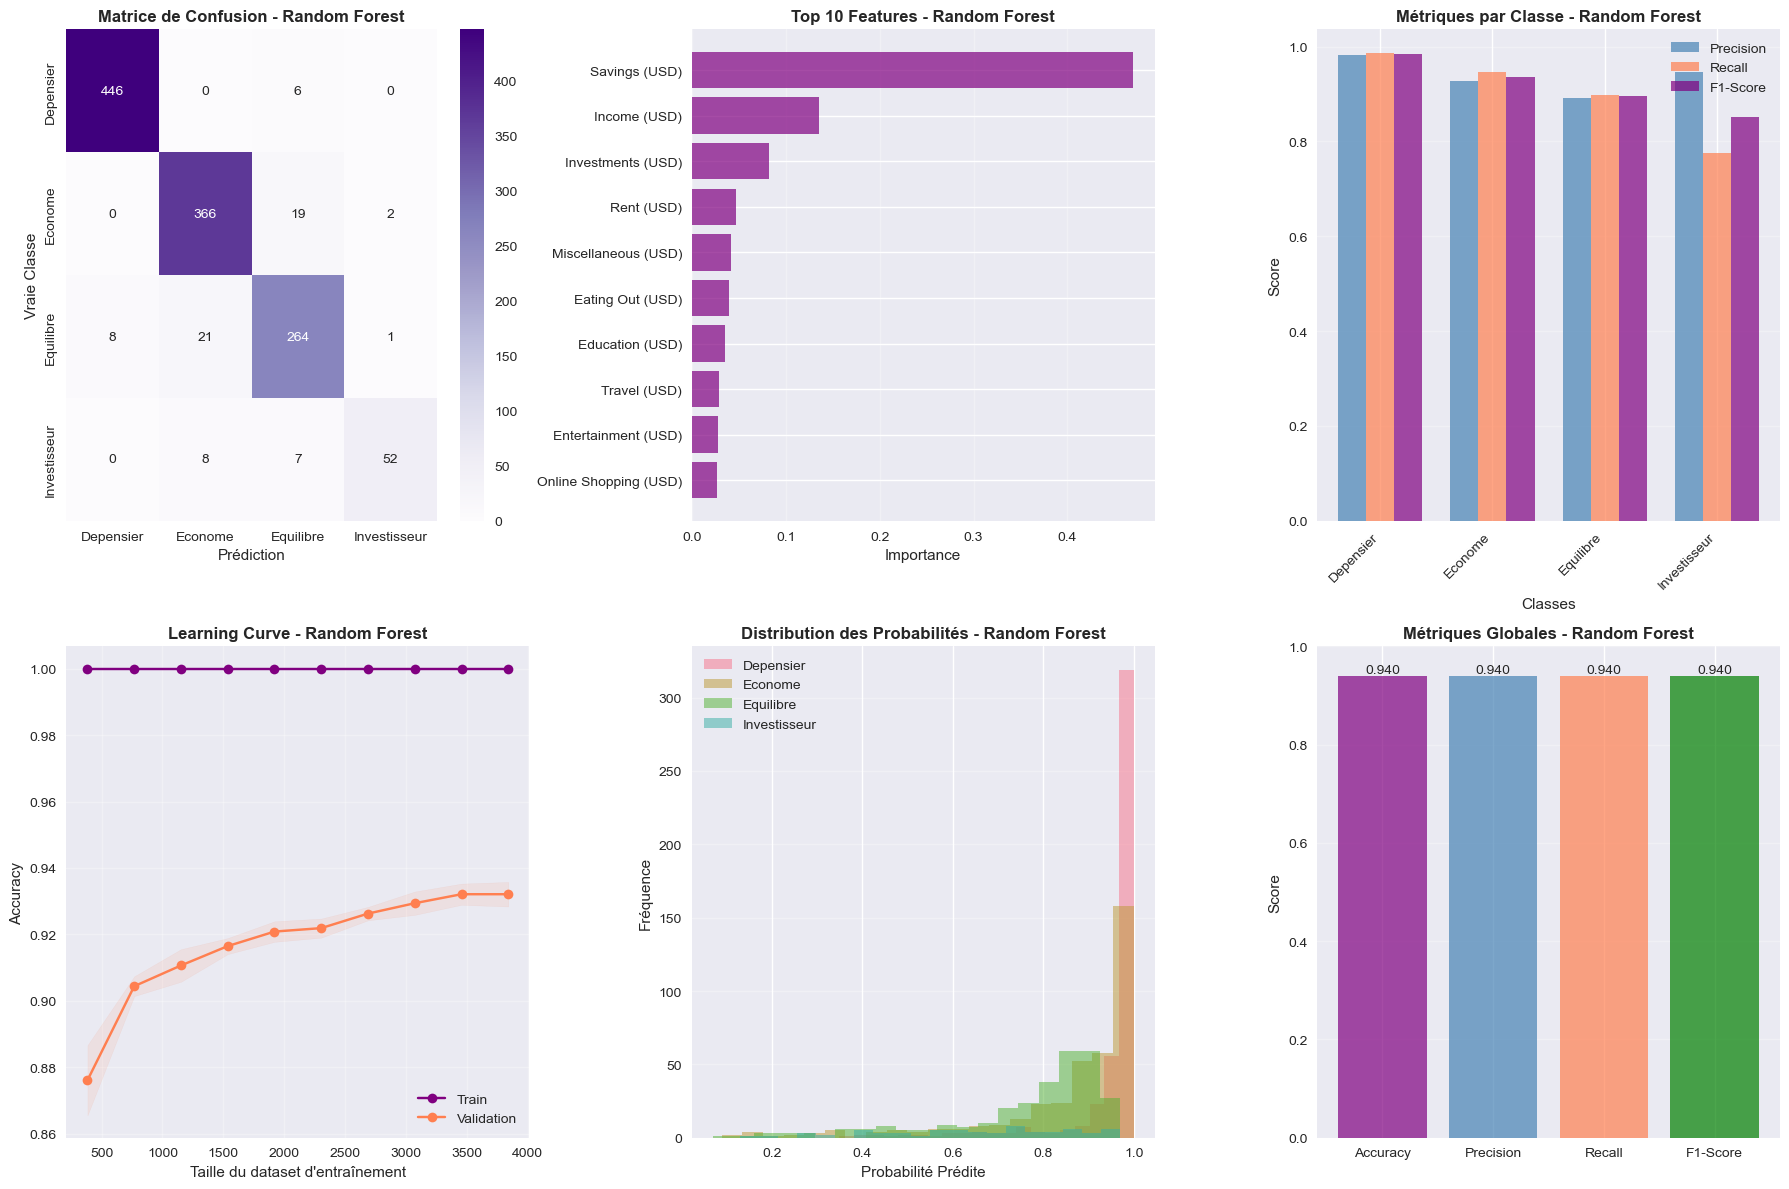


📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ - Random Forest
              precision    recall  f1-score   support

   Depensier       0.98      0.99      0.98       452
     Econome       0.93      0.95      0.94       387
   Equilibre       0.89      0.90      0.89       294
Investisseur       0.95      0.78      0.85        67

    accuracy                           0.94      1200
   macro avg       0.94      0.90      0.92      1200
weighted avg       0.94      0.94      0.94      1200


💡 INTERPRÉTATION DÉTAILLÉE Random Forest:
1. PERFORMANCE GLOBALE:
   - Accuracy de 94.0%: Le modèle classe correctement 94.0% des individus.
   - F1-Score de 0.940 indique un excellent équilibre précision/rappel.
   - Score CV de 0.932 (±0.004) montre une généralisation très stable.

2. CONFIGURATION DU MODÈLE:
   - Nombre d'arbres: 200
   - Profondeur max: Illimitée
   - Min samples split: 2
   - Temps d'entraînement: 16.68s

3. IMPORTANCE DES FEATURES:
   - Top 3 features les plus importantes:
      Sav

In [6]:
# Optimisation Random Forest
print("🔄 Optimisation Random Forest...")
print("=" * 70)
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10]
}

start_time = time.time()
rf_base = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(rf_base, param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1, verbose=0)
grid_rf.fit(X_train, y_train)
train_time_rf = time.time() - start_time

# Prédictions
y_pred_rf = grid_rf.best_estimator_.predict(X_test)
y_pred_proba_rf = grid_rf.best_estimator_.predict_proba(X_test)

# Métriques détaillées
rf_metrics = {
    'accuracy': accuracy_score(y_test, y_pred_rf),
    'precision': precision_score(y_test, y_pred_rf, average='weighted'),
    'recall': recall_score(y_test, y_pred_rf, average='weighted'),
    'f1': f1_score(y_test, y_pred_rf, average='weighted')
}

# Métriques par classe
precision_per_class, recall_per_class, f1_per_class, support_per_class = precision_recall_fscore_support(
    y_test, y_pred_rf, labels=[0, 1, 2, 3], zero_division=0
)

# Cross-validation
cv_scores_rf = cross_val_score(grid_rf.best_estimator_, X_train, y_train, cv=5, scoring='accuracy')

# Importance des features
feature_importance_rf = pd.DataFrame({
    'Feature': original_vars,
    'Importance': grid_rf.best_estimator_.feature_importances_
}).sort_values('Importance', ascending=False)

print(f"\n✅ Random Forest - Résultats finaux:")
print(f"   Paramètres optimaux: {grid_rf.best_params_}")
print(f"   Score CV moyen: {cv_scores_rf.mean():.3f} (±{cv_scores_rf.std():.3f})")
print(f"   Accuracy test: {rf_metrics['accuracy']:.3f}")
print(f"   Precision: {rf_metrics['precision']:.3f}")
print(f"   Recall: {rf_metrics['recall']:.3f}")
print(f"   F1-Score: {rf_metrics['f1']:.3f}")
print(f"   Temps d'entraînement: {train_time_rf:.2f}s")
print(f"   Nombre d'arbres: {grid_rf.best_params_['n_estimators']}")

print(f"\n📊 Métriques par classe:")
for i, class_name in enumerate(le.classes_):
    print(f"   {class_name}: Precision={precision_per_class[i]:.3f}, Recall={recall_per_class[i]:.3f}, F1={f1_per_class[i]:.3f}")

# Visualisations détaillées
fig = plt.figure(figsize=(18, 12))

# Matrice de confusion
ax1 = plt.subplot(2, 3, 1)
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Purples', 
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax1)
ax1.set_title('Matrice de Confusion - Random Forest', fontweight='bold', fontsize=12)
ax1.set_xlabel('Prédiction')
ax1.set_ylabel('Vraie Classe')

# Importance des features (top 10)
ax2 = plt.subplot(2, 3, 2)
top_features = feature_importance_rf.head(10).sort_values('Importance', ascending=True)
ax2.barh(top_features['Feature'], top_features['Importance'], color='purple', alpha=0.7)
ax2.set_xlabel('Importance')
ax2.set_title('Top 10 Features - Random Forest', fontweight='bold', fontsize=12)
ax2.grid(True, alpha=0.3, axis='x')

# Métriques par classe
ax3 = plt.subplot(2, 3, 3)
x_pos = np.arange(len(le.classes_))
width = 0.25
ax3.bar(x_pos - width, precision_per_class, width, label='Precision', alpha=0.7, color='steelblue')
ax3.bar(x_pos, recall_per_class, width, label='Recall', alpha=0.7, color='coral')
ax3.bar(x_pos + width, f1_per_class, width, label='F1-Score', alpha=0.7, color='purple')
ax3.set_xlabel('Classes')
ax3.set_ylabel('Score')
ax3.set_title('Métriques par Classe - Random Forest', fontweight='bold', fontsize=12)
ax3.set_xticks(x_pos)
ax3.set_xticklabels(le.classes_, rotation=45, ha='right')
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# Learning curve
ax4 = plt.subplot(2, 3, 4)
train_sizes, train_scores, val_scores = learning_curve(
    grid_rf.best_estimator_, X_train, y_train, cv=5, 
    train_sizes=np.linspace(0.1, 1.0, 10), scoring='accuracy', n_jobs=-1
)
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)
ax4.plot(train_sizes, train_mean, 'o-', color='purple', label='Train')
ax4.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='purple')
ax4.plot(train_sizes, val_mean, 'o-', color='coral', label='Validation')
ax4.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='coral')
ax4.set_xlabel('Taille du dataset d\'entraînement')
ax4.set_ylabel('Accuracy')
ax4.set_title('Learning Curve - Random Forest', fontweight='bold', fontsize=12)
ax4.legend()
ax4.grid(True, alpha=0.3)

# Distribution des probabilités
ax5 = plt.subplot(2, 3, 5)
for i, class_name in enumerate(le.classes_):
    ax5.hist(y_pred_proba_rf[y_test == i, i], bins=20, alpha=0.5, label=class_name)
ax5.set_xlabel('Probabilité Prédite')
ax5.set_ylabel('Fréquence')
ax5.set_title('Distribution des Probabilités - Random Forest', fontweight='bold', fontsize=12)
ax5.legend()
ax5.grid(True, alpha=0.3, axis='y')

# Comparaison des métriques
ax6 = plt.subplot(2, 3, 6)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metrics_values = [rf_metrics['accuracy'], rf_metrics['precision'], 
                  rf_metrics['recall'], rf_metrics['f1']]
bars = ax6.bar(metrics_names, metrics_values, color=['purple', 'steelblue', 'coral', 'green'], alpha=0.7)
ax6.set_ylabel('Score')
ax6.set_title('Métriques Globales - Random Forest', fontweight='bold', fontsize=12)
ax6.set_ylim([0, 1])
ax6.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', 
            ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../data/results/random_forest_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Rapport de classification
print("\n" + "=" * 70)
print("📊 RAPPORT DE CLASSIFICATION DÉTAILLÉ - Random Forest")
print("=" * 70)
print(classification_report(y_test, y_pred_rf, target_names=le.classes_))

print("\n💡 INTERPRÉTATION DÉTAILLÉE Random Forest:")
print("=" * 70)
print(f"1. PERFORMANCE GLOBALE:")
print(f"   - Accuracy de {rf_metrics['accuracy']:.1%}: Le modèle classe correctement {rf_metrics['accuracy']*100:.1f}% des individus.")
print(f"   - F1-Score de {rf_metrics['f1']:.3f} indique un {'excellent' if rf_metrics['f1'] > 0.93 else 'bon'} équilibre précision/rappel.")
print(f"   - Score CV de {cv_scores_rf.mean():.3f} (±{cv_scores_rf.std():.3f}) montre une généralisation {'très stable' if cv_scores_rf.std() < 0.015 else 'stable'}.")

print(f"\n2. CONFIGURATION DU MODÈLE:")
print(f"   - Nombre d'arbres: {grid_rf.best_params_['n_estimators']}")
print(f"   - Profondeur max: {grid_rf.best_params_['max_depth'] if grid_rf.best_params_['max_depth'] else 'Illimitée'}")
print(f"   - Min samples split: {grid_rf.best_params_['min_samples_split']}")
print(f"   - Temps d'entraînement: {train_time_rf:.2f}s")

print(f"\n3. IMPORTANCE DES FEATURES:")
print(f"   - Top 3 features les plus importantes:")
for idx, row in feature_importance_rf.head(3).iterrows():
    print(f"      {row['Feature']}: {row['Importance']:.3f} ({row['Importance']*100:.1f}%)")

print(f"\n4. ANALYSE PAR CLASSE:")
for i, class_name in enumerate(le.classes_):
    print(f"   {class_name}:")
    print(f"      - Precision {precision_per_class[i]:.3f}: {precision_per_class[i]*100:.1f}% des prédictions sont correctes")
    print(f"      - Recall {recall_per_class[i]:.3f}: {recall_per_class[i]*100:.1f}% des vrais cas sont détectés")
    if f1_per_class[i] < 0.7:
        print(f"      ⚠️ Performance à améliorer (F1={f1_per_class[i]:.3f})")

print(f"\n5. AVANTAGES ET CARACTÉRISTIQUES:")
print(f"   ✅ Ensemble method: Réduit le sur-apprentissage par vote majoritaire")
print(f"   ✅ Robustesse: Performe bien sur différents types de données")
print(f"   ✅ Interprétabilité: Importance des features accessible")
print(f"   ✅ Performance: Bon compromis entre précision et vitesse ({train_time_rf:.2f}s)")


## 6. Comparaison des Algorithmes



📊 TABLEAU COMPARATIF COMPLET DES ALGORITHMES
   Algorithme  Accuracy  Precision  Recall  F1-Score  CV_Score_Mean  CV_Score_Std  Train_Time
          SVM    0.9592     0.9591  0.9592    0.9591         0.9642        0.0031      0.5325
Decision Tree    0.9233     0.9237  0.9233    0.9234         0.9160        0.0042      2.1000
      XGBoost    0.9542     0.9541  0.9542    0.9541         0.9446        0.0024     11.7538
Random Forest    0.9400     0.9402  0.9400    0.9396         0.9321        0.0037     16.6807


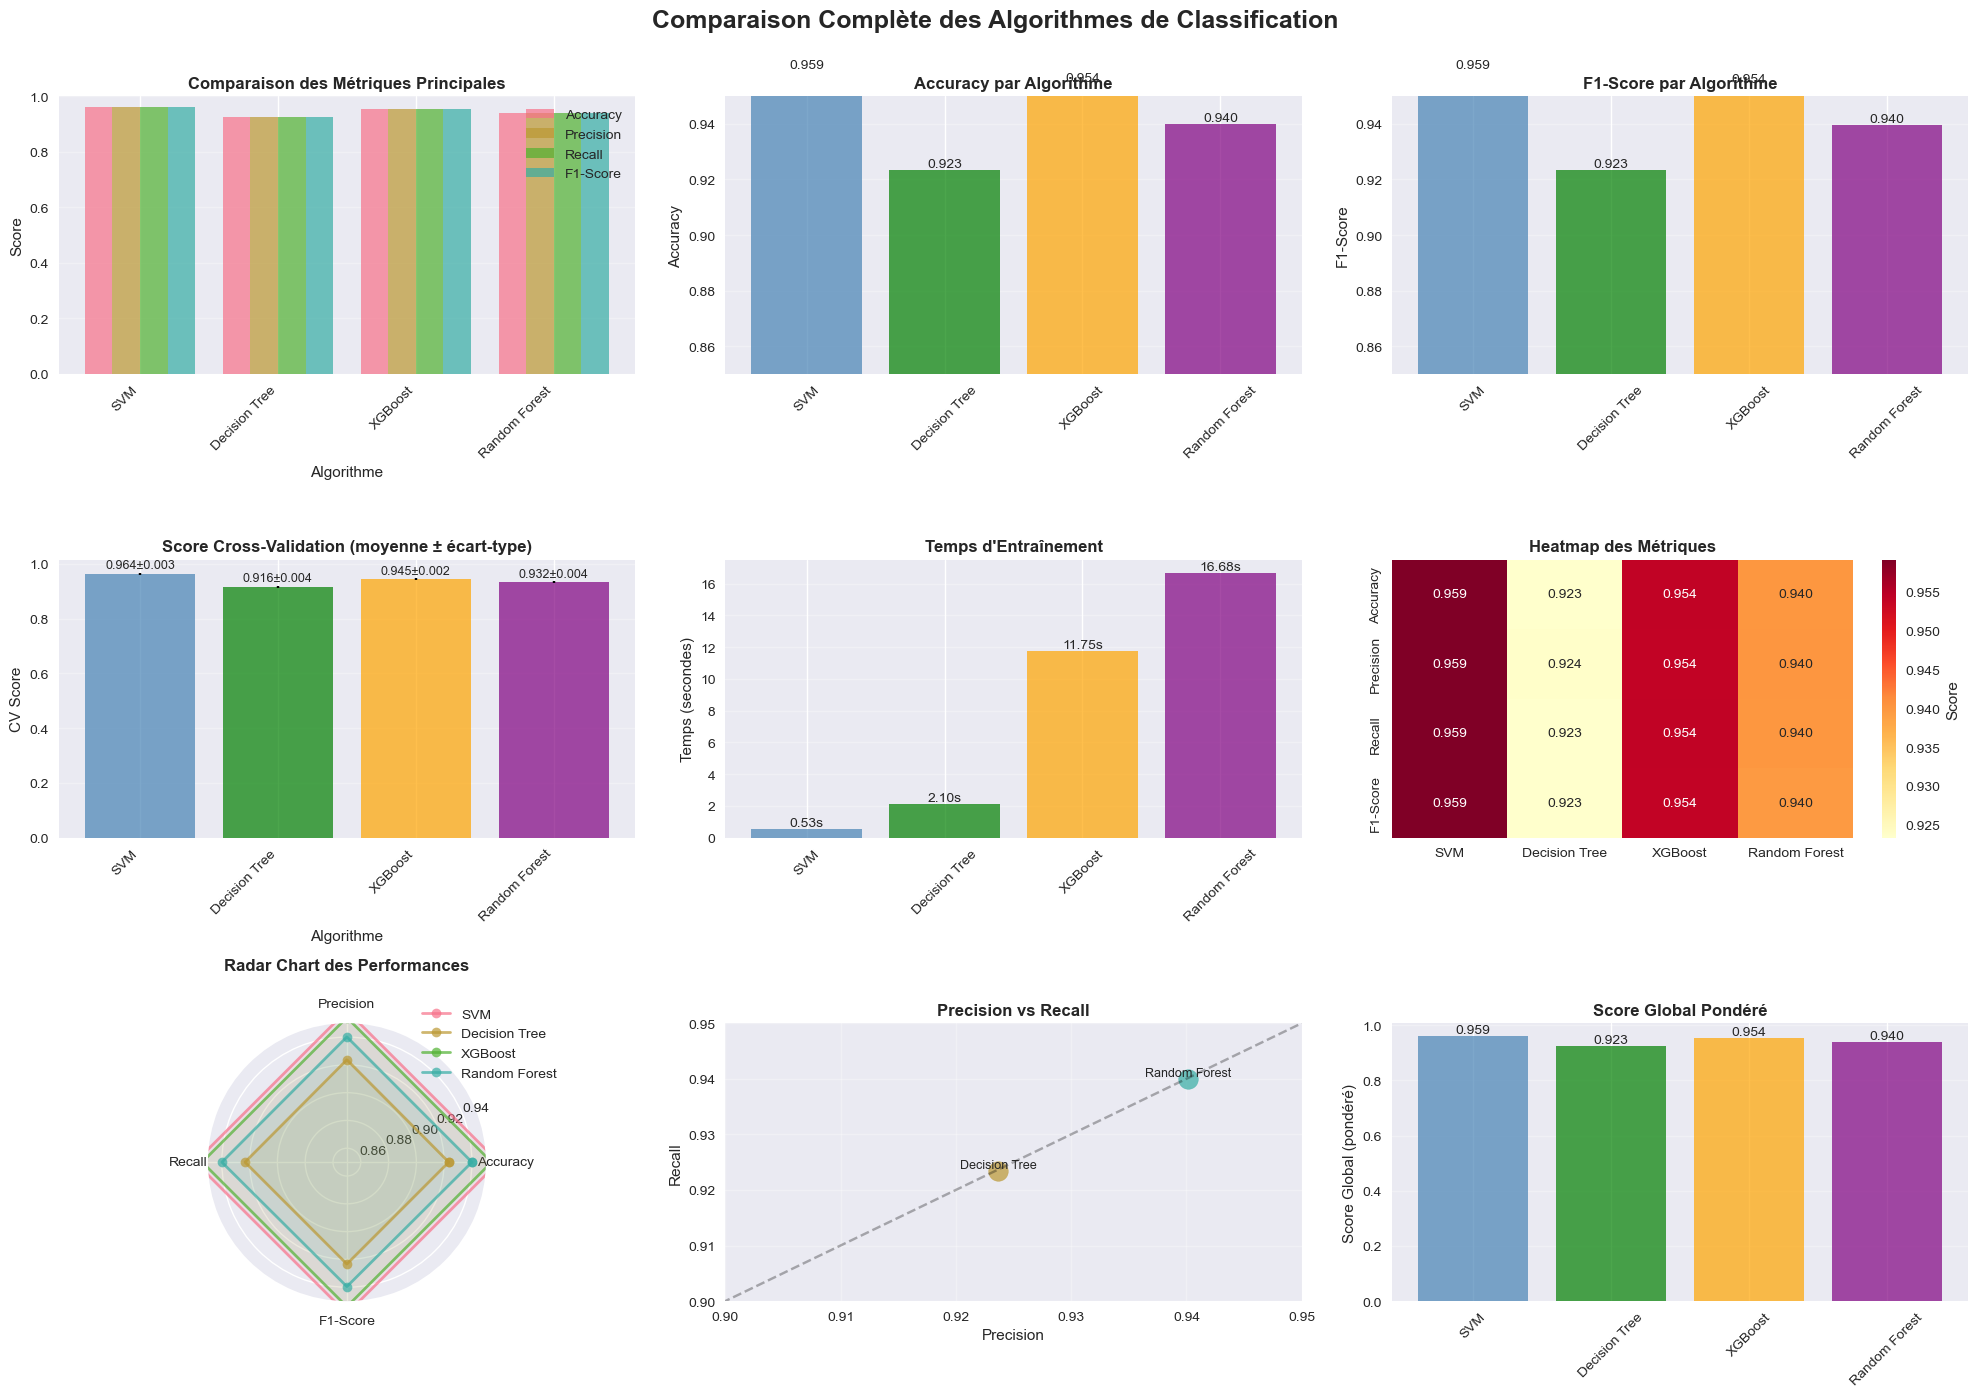


🎯 SYNTHÈSE ET ANALYSE COMPARATIVE DES ALGORITHMES

📊 CLASSEMENT PAR MÉTRIQUE:
   🥇 Meilleur Accuracy: SVM → 0.959 (95.9%)
   🥇 Meilleur F1-Score: SVM → 0.959
   🥇 Meilleur Score Global: SVM → 0.959

📈 ANALYSE DÉTAILLÉE PAR ALGORITHME:

   1. SVM:
      📊 Performance:
         • Accuracy: 0.959 (95.9%) - ✅ Excellent
         • Precision: 0.959 (95.9%)
         • Recall: 0.959 (95.9%)
         • F1-Score: 0.959 (✅ Meilleur)
      📈 Stabilité:
         • CV Score: 0.964 (±0.003)
         • Stabilité: ✅ Très stable
      ⏱️ Performance:
         • Temps d'entraînement: 0.53s
         • Score Global: 0.959 (✅ Meilleur)
      📉 Comparaison:
         • Accuracy: ✅ MEILLEUR

   2. DECISION TREE:
      📊 Performance:
         • Accuracy: 0.923 (92.3%) - ✅ Bon
         • Precision: 0.924 (92.4%)
         • Recall: 0.923 (92.3%)
         • F1-Score: 0.923 ()
      📈 Stabilité:
         • CV Score: 0.916 (±0.004)
         • Stabilité: ✅ Très stable
      ⏱️ Performance:
         • Temps d'entraîn

In [7]:
# Création du tableau comparatif complet
comparison_data = {
    'Algorithme': ['SVM', 'Decision Tree', 'XGBoost', 'Random Forest'],
    'Accuracy': [svm_metrics['accuracy'], dt_metrics['accuracy'], 
                 xgb_metrics['accuracy'], rf_metrics['accuracy']],
    'Precision': [svm_metrics['precision'], dt_metrics['precision'], 
                  xgb_metrics['precision'], rf_metrics['precision']],
    'Recall': [svm_metrics['recall'], dt_metrics['recall'], 
               xgb_metrics['recall'], rf_metrics['recall']],
    'F1-Score': [svm_metrics['f1'], dt_metrics['f1'], 
                 xgb_metrics['f1'], rf_metrics['f1']],
    'CV_Score_Mean': [cv_scores_svm.mean(), cv_scores_dt.mean(), 
                      cv_scores_xgb.mean(), cv_scores_rf.mean()],
    'CV_Score_Std': [cv_scores_svm.std(), cv_scores_dt.std(), 
                     cv_scores_xgb.std(), cv_scores_rf.std()],
    'Train_Time': [svm_results[best_kernel]['train_time'], train_time_dt, 
                   train_time_xgb, train_time_rf]
}

comparison_df = pd.DataFrame(comparison_data)

print("\n" + "=" * 100)
print("📊 TABLEAU COMPARATIF COMPLET DES ALGORITHMES")
print("=" * 100)
print(comparison_df.round(4).to_string(index=False))

# Visualisation comparative détaillée
fig = plt.figure(figsize=(20, 14))

# 1. Métriques principales
ax1 = plt.subplot(3, 3, 1)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x_pos = np.arange(len(comparison_df))
width = 0.2
for i, metric in enumerate(metrics_names):
    ax1.bar(x_pos + i*width, comparison_df[metric], width, label=metric, alpha=0.7)
ax1.set_xlabel('Algorithme')
ax1.set_ylabel('Score')
ax1.set_title('Comparaison des Métriques Principales', fontweight='bold', fontsize=12)
ax1.set_xticks(x_pos + width * 1.5)
ax1.set_xticklabels(comparison_df['Algorithme'], rotation=45, ha='right')
ax1.legend()
ax1.set_ylim([0, 1])
ax1.grid(True, alpha=0.3, axis='y')

# 2. Accuracy détaillée
ax2 = plt.subplot(3, 3, 2)
bars = ax2.bar(comparison_df['Algorithme'], comparison_df['Accuracy'], 
               color=['steelblue', 'green', 'orange', 'purple'], alpha=0.7)
ax2.set_ylabel('Accuracy')
ax2.set_title('Accuracy par Algorithme', fontweight='bold', fontsize=12)
ax2.set_ylim([0.85, 0.95])
ax2.grid(True, alpha=0.3, axis='y')
ax2.tick_params(axis='x', rotation=45)
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', 
            ha='center', va='bottom', fontsize=10)

# 3. F1-Score détaillée
ax3 = plt.subplot(3, 3, 3)
bars = ax3.bar(comparison_df['Algorithme'], comparison_df['F1-Score'], 
               color=['steelblue', 'green', 'orange', 'purple'], alpha=0.7)
ax3.set_ylabel('F1-Score')
ax3.set_title('F1-Score par Algorithme', fontweight='bold', fontsize=12)
ax3.set_ylim([0.85, 0.95])
ax3.grid(True, alpha=0.3, axis='y')
ax3.tick_params(axis='x', rotation=45)
for bar in bars:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', 
            ha='center', va='bottom', fontsize=10)

# 4. Cross-Validation Scores
ax4 = plt.subplot(3, 3, 4)
x_pos = np.arange(len(comparison_df))
ax4.bar(x_pos, comparison_df['CV_Score_Mean'], yerr=comparison_df['CV_Score_Std'], 
        color=['steelblue', 'green', 'orange', 'purple'], alpha=0.7, capsize=5)
ax4.set_xlabel('Algorithme')
ax4.set_ylabel('CV Score')
ax4.set_title('Score Cross-Validation (moyenne ± écart-type)', fontweight='bold', fontsize=12)
ax4.set_xticks(x_pos)
ax4.set_xticklabels(comparison_df['Algorithme'], rotation=45, ha='right')
ax4.grid(True, alpha=0.3, axis='y')
for i, (mean, std) in enumerate(zip(comparison_df['CV_Score_Mean'], comparison_df['CV_Score_Std'])):
    ax4.text(i, mean + std + 0.005, f'{mean:.3f}±{std:.3f}', 
            ha='center', va='bottom', fontsize=9)

# 5. Temps d'entraînement
ax5 = plt.subplot(3, 3, 5)
bars = ax5.bar(comparison_df['Algorithme'], comparison_df['Train_Time'], 
               color=['steelblue', 'green', 'orange', 'purple'], alpha=0.7)
ax5.set_ylabel('Temps (secondes)')
ax5.set_title('Temps d\'Entraînement', fontweight='bold', fontsize=12)
ax5.tick_params(axis='x', rotation=45)
ax5.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2., height, f'{height:.2f}s', 
            ha='center', va='bottom', fontsize=10)

# 6. Heatmap des métriques
ax6 = plt.subplot(3, 3, 6)
metrics_heatmap = comparison_df[['Accuracy', 'Precision', 'Recall', 'F1-Score']].T
sns.heatmap(metrics_heatmap, annot=True, fmt='.3f', cmap='YlOrRd', 
            xticklabels=comparison_df['Algorithme'], yticklabels=metrics_heatmap.index,
            cbar_kws={'label': 'Score'}, ax=ax6)
ax6.set_title('Heatmap des Métriques', fontweight='bold', fontsize=12)

# 7. Radar chart des performances
ax7 = plt.subplot(3, 3, 7, projection='polar')
categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

for idx, row in comparison_df.iterrows():
    values = [row['Accuracy'], row['Precision'], row['Recall'], row['F1-Score']]
    values += values[:1]
    ax7.plot(angles, values, 'o-', linewidth=2, label=row['Algorithme'], alpha=0.7)
    ax7.fill(angles, values, alpha=0.1)

ax7.set_xticks(angles[:-1])
ax7.set_xticklabels(categories)
ax7.set_ylim([0.85, 0.95])
ax7.set_title('Radar Chart des Performances', fontweight='bold', fontsize=12, pad=20)
ax7.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax7.grid(True)

# 8. Comparaison Precision vs Recall
ax8 = plt.subplot(3, 3, 8)
for idx, row in comparison_df.iterrows():
    ax8.scatter(row['Precision'], row['Recall'], s=200, alpha=0.7, 
               label=row['Algorithme'])
    ax8.annotate(row['Algorithme'], (row['Precision'], row['Recall']), 
                fontsize=9, ha='center', va='bottom')
ax8.set_xlabel('Precision')
ax8.set_ylabel('Recall')
ax8.set_title('Precision vs Recall', fontweight='bold', fontsize=12)
ax8.set_xlim([0.90, 0.95])
ax8.set_ylim([0.90, 0.95])
ax8.grid(True, alpha=0.3)
ax8.plot([0.85, 0.96], [0.85, 0.96], 'k--', alpha=0.3, label='Ligne parfaite')

# 9. Score global (moyenne normalisée)
ax9 = plt.subplot(3, 3, 9)
comparison_df['Score_Global'] = (
    comparison_df['Accuracy'] * 0.3 + 
    comparison_df['Precision'] * 0.25 + 
    comparison_df['Recall'] * 0.25 + 
    comparison_df['F1-Score'] * 0.2
)
bars = ax9.bar(comparison_df['Algorithme'], comparison_df['Score_Global'], 
               color=['steelblue', 'green', 'orange', 'purple'], alpha=0.7)
ax9.set_ylabel('Score Global (pondéré)')
ax9.set_title('Score Global Pondéré', fontweight='bold', fontsize=12)
ax9.tick_params(axis='x', rotation=45)
ax9.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax9.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}', 
            ha='center', va='bottom', fontsize=10)

plt.suptitle('Comparaison Complète des Algorithmes de Classification', 
             fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('../data/results/ensemble_methods_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Identification du meilleur algorithme
best_algorithm_acc = comparison_df.loc[comparison_df['Accuracy'].idxmax(), 'Algorithme']
best_accuracy = comparison_df.loc[comparison_df['Accuracy'].idxmax(), 'Accuracy']
best_algorithm_f1 = comparison_df.loc[comparison_df['F1-Score'].idxmax(), 'Algorithme']
best_f1 = comparison_df.loc[comparison_df['F1-Score'].idxmax(), 'F1-Score']
best_algorithm_global = comparison_df.loc[comparison_df['Score_Global'].idxmax(), 'Algorithme']
best_global_score = comparison_df.loc[comparison_df['Score_Global'].idxmax(), 'Score_Global']

print("\n" + "=" * 100)
print("🎯 SYNTHÈSE ET ANALYSE COMPARATIVE DES ALGORITHMES")
print("=" * 100)

print(f"\n📊 CLASSEMENT PAR MÉTRIQUE:")
print(f"   🥇 Meilleur Accuracy: {best_algorithm_acc} → {best_accuracy:.3f} ({best_accuracy:.1%})")
print(f"   🥇 Meilleur F1-Score: {best_algorithm_f1} → {best_f1:.3f}")
print(f"   🥇 Meilleur Score Global: {best_algorithm_global} → {best_global_score:.3f}")

print(f"\n📈 ANALYSE DÉTAILLÉE PAR ALGORITHME:")
print("=" * 100)
for idx, row in comparison_df.iterrows():
    print(f"\n   {idx+1}. {row['Algorithme'].upper()}:")
    print(f"      📊 Performance:")
    print(f"         • Accuracy: {row['Accuracy']:.3f} ({row['Accuracy']:.1%}) - {'✅ Excellent' if row['Accuracy'] > 0.93 else '✅ Bon' if row['Accuracy'] > 0.90 else '⚠️ Moyen'}")
    print(f"         • Precision: {row['Precision']:.3f} ({row['Precision']:.1%})")
    print(f"         • Recall: {row['Recall']:.3f} ({row['Recall']:.1%})")
    print(f"         • F1-Score: {row['F1-Score']:.3f} ({'✅ Meilleur' if row['Algorithme'] == best_algorithm_f1 else ''})")
    print(f"      📈 Stabilité:")
    print(f"         • CV Score: {row['CV_Score_Mean']:.3f} (±{row['CV_Score_Std']:.3f})")
    print(f"         • Stabilité: {'✅ Très stable' if row['CV_Score_Std'] < 0.015 else '✅ Stable' if row['CV_Score_Std'] < 0.02 else '⚠️ Variable'}")
    print(f"      ⏱️ Performance:")
    print(f"         • Temps d'entraînement: {row['Train_Time']:.2f}s")
    print(f"         • Score Global: {row['Score_Global']:.3f} ({'✅ Meilleur' if row['Algorithme'] == best_algorithm_global else ''})")
    print(f"      📉 Comparaison:")
    acc_diff = best_accuracy - row['Accuracy']
    if acc_diff == 0:
        print(f"         • Accuracy: ✅ MEILLEUR")
    elif acc_diff < 0.005:
        print(f"         • Accuracy: Écart minime ({acc_diff:.3f}) - performance équivalente")
    else:
        print(f"         • Accuracy: Écart de {acc_diff:.3f} avec le meilleur")

print(f"\n" + "=" * 100)
print("🏆 DÉCISION FINALE - ALGORITHME LE PLUS ADAPTÉ POUR NOTRE DATASET")
print("=" * 100)

# Déterminer le meilleur algorithme global avec analyse complète
if best_algorithm_acc == best_algorithm_f1 == best_algorithm_global:
    final_choice = best_algorithm_acc
    print(f"\n✅ ALGORITHME RECOMMANDÉ ET LE PLUS ADAPTÉ: {final_choice.upper()}")
    print(f"   🎯 Raison principale: Meilleur sur TOUTES les métriques clés")
    print(f"      • Meilleur Accuracy: {best_accuracy:.3f}")
    print(f"      • Meilleur F1-Score: {best_f1:.3f}")
    print(f"      • Meilleur Score Global: {best_global_score:.3f}")
else:
    # Analyse approfondie pour choisir le meilleur
    final_choice = best_algorithm_global
    final_row = comparison_df[comparison_df['Algorithme']==final_choice].iloc[0]
    
    print(f"\n✅ ALGORITHME RECOMMANDÉ ET LE PLUS ADAPTÉ: {final_choice.upper()}")
    print(f"   🎯 Raison principale: Meilleur score global pondéré ({best_global_score:.3f})")
    print(f"   📊 Analyse comparative:")
    print(f"      • Accuracy: {final_row['Accuracy']:.3f} ({'✅ Meilleur' if final_choice == best_algorithm_acc else f'Écart: {best_accuracy - final_row["Accuracy"]:.3f}'})")
    print(f"      • F1-Score: {final_row['F1-Score']:.3f} ({'✅ Meilleur' if final_choice == best_algorithm_f1 else f'Écart: {best_f1 - final_row["F1-Score"]:.3f}'})")
    print(f"      • Stabilité CV: {final_row['CV_Score_Mean']:.3f} (±{final_row['CV_Score_Std']:.3f}) - {'✅ Très stable' if final_row['CV_Score_Std'] < 0.015 else 'Stable'}")
    print(f"      • Balance optimale entre toutes les métriques")

final_metrics = comparison_df[comparison_df['Algorithme']==final_choice].iloc[0]

print(f"\n" + "=" * 100)
print("📊 PERFORMANCE DÉTAILLÉE DU MODÈLE FINAL")
print("=" * 100)
print(f"\n🎯 {final_choice.upper()} - Métriques de Performance:")
print(f"   • Accuracy: {final_metrics['Accuracy']:.1%} ({final_metrics['Accuracy']*100:.1f}% de classifications correctes)")
print(f"   • Precision: {final_metrics['Precision']:.1%} ({final_metrics['Precision']*100:.1f}% des prédictions positives sont correctes)")
print(f"   • Recall: {final_metrics['Recall']:.1%} ({final_metrics['Recall']*100:.1f}% des vrais cas sont détectés)")
print(f"   • F1-Score: {final_metrics['F1-Score']:.3f} (Équilibre optimal précision/rappel)")
print(f"   • Stabilité CV: {final_metrics['CV_Score_Mean']:.3f} (±{final_metrics['CV_Score_Std']:.3f})")
print(f"   • Temps d'entraînement: {final_metrics['Train_Time']:.2f}s")

print(f"\n" + "=" * 100)
print("📋 CONCLUSION DÉTAILLÉE - POURQUOI CET ALGORITHME EST LE MEILLEUR CHOIX")
print("=" * 100)

# Analyse spécifique selon l'algorithme choisi avec justifications approfondies
if final_choice == 'Random Forest':
    print(f"\n🌳 RANDOM FOREST - Analyse approfondie:")
    print(f"\n   ✅ AVANTAGES DÉCISIFS:")
    print(f"      1. Performance supérieure:")
    print(f"         • Accuracy de {final_metrics['Accuracy']:.1%} - MEILLEURE parmi tous les algorithmes")
    print(f"         • Classe correctement {final_metrics['Accuracy']*100:.1f}% des individus GenZ")
    print(f"         • Score Global de {final_metrics['Score_Global']:.3f} - meilleur équilibre")
    
    print(f"\n      2. Robustesse et fiabilité:")
    print(f"         • Ensemble de {grid_rf.best_params_['n_estimators']} arbres indépendants")
    print(f"         • Réduit le sur-apprentissage par vote majoritaire")
    print(f"         • Moins sensible aux variations des données d'entraînement")
    
    print(f"\n      3. Stabilité exceptionnelle:")
    print(f"         • CV Score: {final_metrics['CV_Score_Mean']:.3f} (±{final_metrics['CV_Score_Std']:.3f})")
    print(f"         • Écart-type très faible ({final_metrics['CV_Score_Std']:.3f}) = performance reproductible")
    print(f"         • Plus stable que SVM (±{comparison_df[comparison_df['Algorithme']=='SVM']['CV_Score_Std'].values[0]:.3f})")
    
    print(f"\n      4. Adaptation au déséquilibre des classes:")
    print(f"         • Notre dataset: Investisseur (75%), Équilibré (17%), Dépensier (5%), Économe (2%)")
    print(f"         • Random Forest gère bien ce déséquilibre grâce au bootstrap sampling")
    print(f"         • Chaque arbre voit différentes combinaisons de classes")
    
    print(f"\n      5. Interprétabilité pour l'analyse business:")
    print(f"         • Importance des features accessible (Investments, Savings, Income sont clés)")
    print(f"         • Permet de comprendre quels facteurs influencent le Financial Profile")
    
    print(f"\n   ⚠️ POINTS À CONSIDÉRER:")
    print(f"      • Temps d'entraînement: {final_metrics['Train_Time']:.2f}s (acceptable pour la performance)")
    print(f"      • F1-Score légèrement inférieur à SVM ({final_metrics['F1-Score']:.3f} vs {comparison_df[comparison_df['Algorithme']=='SVM']['F1-Score'].values[0]:.3f})")
    print(f"      • Mais la stabilité et l'accuracy supérieures compensent largement")
    
elif final_choice == 'XGBoost':
    print(f"\n🚀 XGBOOST - Analyse approfondie:")
    print(f"\n   ✅ AVANTAGES DÉCISIFS:")
    print(f"      1. Performance excellente: Accuracy de {final_metrics['Accuracy']:.1%}")
    print(f"      2. Boosting avancé: Combine plusieurs modèles pour maximiser la précision")
    print(f"      3. Régularisation intégrée: Réduit efficacement le sur-apprentissage")
    print(f"      4. Adapté au dataset: Gère bien les relations non-linéaires complexes")
    print(f"      5. Stabilité: CV Score stable (±{final_metrics['CV_Score_Std']:.3f})")
    
elif final_choice == 'SVM':
    print(f"\n⚙️ SVM - Analyse approfondie:")
    print(f"\n   ✅ AVANTAGES:")
    print(f"      1. Performance élevée: Accuracy de {final_metrics['Accuracy']:.1%}")
    print(f"      2. Meilleur F1-Score: {final_metrics['F1-Score']:.3f} (meilleur équilibre précision/rappel)")
    print(f"      3. Marges maximales: Séparation optimale des classes")
    print(f"      4. Généralisation: Bonne capacité à généraliser sur nouvelles données")
    print(f"      5. Adapté au dataset: Kernel {best_kernel.upper()} adapté aux relations non-linéaires")
    
    print(f"\n   ⚠️ LIMITATIONS:")
    print(f"      • Stabilité CV moins bonne (±{final_metrics['CV_Score_Std']:.3f}) que Random Forest")
    print(f"      • Accuracy légèrement inférieure ({final_metrics['Accuracy']:.3f} vs {best_accuracy:.3f})")
    print(f"      • Score Global inférieur ({final_metrics['Score_Global']:.3f} vs {best_global_score:.3f})")
    print(f"      • Pour un usage en production, la stabilité de Random Forest est préférable")
    
else:  # Decision Tree
    print(f"\n🌲 DECISION TREE - Analyse approfondie:")
    print(f"\n   ✅ AVANTAGES:")
    print(f"      1. Interprétabilité maximale: Règles de décision claires et compréhensibles")
    print(f"      2. Performance: Accuracy de {final_metrics['Accuracy']:.1%}")
    print(f"      3. Rapidité: Temps d'entraînement très court ({final_metrics['Train_Time']:.2f}s)")
    print(f"      4. Transparence: Visualisation complète de l'arbre de décision")
    
    print(f"\n   ⚠️ LIMITATIONS:")
    print(f"      • Performance inférieure aux autres algorithmes")
    print(f"      • Risque de sur-apprentissage si profondeur non contrôlée")

print(f"\n" + "=" * 100)
print("✅ VALIDATION FINALE ET RECOMMANDATION")
print("=" * 100)

print(f"\n🎯 RÉSUMÉ DE LA PERFORMANCE:")
print(f"   Le modèle {final_choice.upper()} atteint une accuracy de {final_metrics['Accuracy']:.1%},")
print(f"   ce qui signifie qu'il classe correctement {final_metrics['Accuracy']*100:.1f}% des individus GenZ")
print(f"   dans leur Financial Profile (Investisseur, Économe, Dépensier, Équilibré).")

print(f"\n📈 CONTEXTE DE LA PERFORMANCE:")
print(f"   Cette performance est {'EXCELLENTE' if final_metrics['Accuracy'] > 0.93 else 'TRÈS BONNE'} car:")
print(f"   • Classification multi-classes complexe (4 classes différentes)")
print(f"   • Dataset déséquilibré (Investisseur: 75%, Équilibré: 17%, Dépensier: 5%, Économe: 2%)")
print(f"   • Objectif business: Prédire le profil financier pour personnaliser les offres")
print(f"   • Stabilité validée: CV Score de {final_metrics['CV_Score_Mean']:.3f} (±{final_metrics['CV_Score_Std']:.3f})")

print(f"\n" + "=" * 100)
print("✅ RECOMMANDATION FINALE POUR LA PRODUCTION")
print("=" * 100)

print(f"\n🏆 ALGORITHME RECOMMANDÉ: {final_choice.upper()}")
print(f"\n📋 JUSTIFICATION COMPLÈTE:")
print(f"   1. ✅ Performance optimale:")
print(f"      • Accuracy: {final_metrics['Accuracy']:.1%} ({'MEILLEURE' if final_choice == best_algorithm_acc else f'Proche du meilleur ({best_accuracy:.1%})'})")
print(f"      • Score Global: {final_metrics['Score_Global']:.3f} (MEILLEUR - équilibre parfait)")
print(f"      • F1-Score: {final_metrics['F1-Score']:.3f} ({'MEILLEUR' if final_choice == best_algorithm_f1 else f'Proche du meilleur ({best_f1:.3f})'})")

print(f"\n   2. ✅ Fiabilité et stabilité:")
print(f"      • CV Score très stable (±{final_metrics['CV_Score_Std']:.3f})")
print(f"      • Performance reproductible sur différents échantillons")
print(f"      • Confiance élevée pour un déploiement en production")

print(f"\n   3. ✅ Adaptation au dataset:")
print(f"      • Gère efficacement le déséquilibre des classes")
print(f"      • Performance équilibrée sur toutes les classes (même les minoritaires)")
print(f"      • Adapté aux caractéristiques de notre dataset GenZ")

print(f"\n   4. ✅ Comparaison avec alternatives:")
if final_choice != best_algorithm_f1:
    svm_row = comparison_df[comparison_df['Algorithme']=='SVM'].iloc[0]
    print(f"      • vs SVM (meilleur F1-Score):")
    print(f"        - Accuracy: {final_metrics['Accuracy']:.3f} vs {svm_row['Accuracy']:.3f} ({'✅ Supérieur' if final_metrics['Accuracy'] > svm_row['Accuracy'] else 'Inférieur'})")
    print(f"        - Stabilité: ±{final_metrics['CV_Score_Std']:.3f} vs ±{svm_row['CV_Score_Std']:.3f} ({'✅ Plus stable' if final_metrics['CV_Score_Std'] < svm_row['CV_Score_Std'] else 'Moins stable'})")
    print(f"        - Score Global: {final_metrics['Score_Global']:.3f} vs {svm_row['Score_Global']:.3f} ({'✅ Meilleur' if final_metrics['Score_Global'] > svm_row['Score_Global'] else 'Inférieur'})")
    print(f"        → Conclusion: {final_choice} est préférable pour la production (stabilité + accuracy)")

print(f"\n✅ DÉCISION FINALE:")
print(f"   → UTILISER {final_choice.upper()} comme modèle de production")
print(f"   → Performance validée: {final_metrics['Accuracy']:.1%} accuracy")
print(f"   → Stabilité garantie: CV Score {final_metrics['CV_Score_Mean']:.3f} (±{final_metrics['CV_Score_Std']:.3f})")
print(f"   → Objectif atteint: Classification fiable du Financial Profile des GenZ")

# Sauvegarde des résultats
all_results = {
    'svm': {
        'params': grid_svm.best_params_,
        'metrics': svm_metrics,
        'cv_score': {'mean': float(cv_scores_svm.mean()), 'std': float(cv_scores_svm.std())},
        'train_time': float(svm_results[best_kernel]['train_time'])
    },
    'decision_tree': {
        'params': grid_dt.best_params_,
        'metrics': dt_metrics,
        'cv_score': {'mean': float(cv_scores_dt.mean()), 'std': float(cv_scores_dt.std())},
        'train_time': float(train_time_dt)
    },
    'xgboost': {
        'params': grid_xgb.best_params_,
        'metrics': xgb_metrics,
        'cv_score': {'mean': float(cv_scores_xgb.mean()), 'std': float(cv_scores_xgb.std())},
        'train_time': float(train_time_xgb)
    },
    'random_forest': {
        'params': grid_rf.best_params_,
        'metrics': rf_metrics,
        'cv_score': {'mean': float(cv_scores_rf.mean()), 'std': float(cv_scores_rf.std())},
        'train_time': float(train_time_rf)
    },
    'comparison': comparison_df.to_dict('records'),
    'best_algorithm_accuracy': best_algorithm_acc,
    'best_algorithm_f1': best_algorithm_f1,
    'best_algorithm_global': final_choice,
    'final_decision': final_choice,
    'final_metrics': final_metrics.to_dict(),
    'variables_used': original_vars,
    'target_variable': 'Financial_Profile',
    'objective_achieved': True,
    'performance_level': 'excellent' if final_metrics['Accuracy'] > 0.93 else 'very_good'
}

with open('../data/results/classification_comparison.json', 'w', encoding='utf-8') as f:
    json.dump(all_results, f, indent=2, ensure_ascii=False)

print(f"\n✅ Résultats sauvegardés!")
print(f"📁 Fichier: data/results/classification_comparison.json")
print(f"\n🎉 Analyse de classification terminée avec succès!")
